# Underwater image enhancement (UIEB) with the CPDM architecture

* **Model**: CPDM (*Content-Preserving Diffusion Model for Underwater Image Enhancement*) from `GZHU-DVL/CPDM`, architecture unchanged (Section 1). A conditional DDPM: a 9-channel guided-diffusion `UNetModel` (128 base channels, 3 res-blocks per level, channel multipliers 1-2-3-4, attention at 4x / 8x down-sampling) whose input is `[x_t, I, I - x_t]` (noisy clean-image estimate, degraded image, their difference), plus CPDM's own `conv1_*_1` layers that re-inject the degraded image `I` into the encoder after every resolution level. 1000-step cosine noise schedule, epsilon prediction.
* **Training recipe**: same data pipeline, split, augmentation, optimiser (Adam), scheduler (ReduceLROnPlateau) and early stopping as the other models of this series. The **loss is the one exception**: CPDM is trained with the repository's diffusion objective (epsilon-MSE at a random timestep, timesteps drawn with the `loss-second-moment` sampler from `train.sh`), not L1 + SSIM (Section 2). Like the repository, validation / test use an **EMA copy** of the weights.
* **Training loop** (Section 4) follows `ASRD_U_Mamba.ipynb`: after every epoch it prints the loss and all 4 metrics (PSNR, SSIM, LPIPS, UIQM) for train and validation, writes one CSV row, keeps **only the single best model** (highest validation PSNR) and stops early after `PATIENCE` epochs without improvement. There are no checkpoints and no resume.

What is different from a single-output model such as WaterNet:

| | CPDM |
|---|---|
| training forward | one network call on a noisy ground truth `x_t` at a random timestep `t`; the loss is MSE between the true and the predicted noise |
| **train** metrics | measured on the network's one-step estimate of the clean image (`x0` implied by the predicted noise) at the sampled `t`, so they depend on `t` and are *not* comparable to the val / test numbers |
| val / test metrics | full reverse diffusion (ancestral sampling, `p_sample_loop`) from noise, conditioned on the degraded image; 8-bit quantised like every other model |
| val "loss" | L1(final image, GT); the diffusion loss needs a noise target which does not exist at inference |
| sampling steps | `CPDM_SAMPLE_STEPS_VAL` for validation, `CPDM_SAMPLE_STEPS_TEST` (1000 = repository setting) for the test set |
| precision | `torch.autocast` (fp16) for the UNet, float32 weights and diffusion arithmetic |

Files written under `Dehaze/`:

| file | content |
|---|---|
| `logs/training_log.csv` | one row per epoch: LR, train loss + PSNR/SSIM/LPIPS/UIQM, val loss + PSNR/SSIM/LPIPS/UIQM, timings, throughput, GPU memory, `is_best` |
| `logs/metrics_test.csv` | final test metrics |
| `logs/timing_summary.csv` | training time, inference latency / FPS, parameters, MACs |
| `logs/comparison_metrics.csv` | per-image metrics for the qualitative comparison |
| `models/data_split.csv` | train/val/test file lists |
| `models/best_model_cpdm.pth` | best model (EMA `state_dict`, selected by validation PSNR) |

# Imports

In [1]:
# %pip install -q lpips thop scikit-image opencv-python scipy   # uncomment on a fresh environment
import sys
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
# Memory optimization: reduce fragmentation on small GPUs
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
import time
import csv
import copy
import math
import random
import datetime
from pathlib import Path

from tqdm.auto import tqdm
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from scipy import ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint as torch_checkpoint

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import lpips  # pip install lpips

c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PROJECT_ROOT = os.path.abspath(".")
DATASET_ROOT = os.path.join(PROJECT_ROOT, "dataset")
RAW_DIR = os.path.join(DATASET_ROOT, "raw-890")          # degraded inputs
REF_DIR = os.path.join(DATASET_ROOT, "reference-890")    # clean reference images (same file names)
MODEL_SAVE_DIR = os.path.join(PROJECT_ROOT, "Dehaze", "models")
LOG_DIR = os.path.join(PROJECT_ROOT, "Dehaze", "logs")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "Dehaze", "comparison_outputs")
for d in [MODEL_SAVE_DIR, LOG_DIR, OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)

# ---- data / optimisation
IMG_SIZE = 256
BATCH_SIZE = 2  # Physical batch size (what fits in GPU memory)
GRADIENT_ACCUM_STEPS = 4  # Accumulate gradients over 4 steps
# Effective batch size = BATCH_SIZE * GRADIENT_ACCUM_STEPS = 2 * 4 = 8
EPOCHS = 100
LR = 1e-4
WEIGHT_DECAY = 1e-5
LR_PATIENCE = 5
LR_FACTOR = 0.5
LR_MIN = 1e-6

# ---- CPDM configuration: the flags of train.sh / sample.sh of the repository (architecture unchanged)
CPDM_NUM_CHANNELS = 128            # --num_channels 128
CPDM_NUM_RES_BLOCKS = 3            # --num_res_blocks 3
CPDM_CHANNEL_MULT = "1,2,3,4"      # the repository's choice for 64 px; CPDM's conv1_*_1 layers hard-code 4 levels / 128-256-384-512 channels
CPDM_NUM_HEADS = 4                 # repo default
CPDM_DROPOUT = 0.0                 # repo default
# Attention sits at 4x and 8x down-sampling (repo default "16,8" is defined as image_size // 16, // 8 for the 64 px images).
# Scaled with IMG_SIZE so that the architecture is the same at any resolution; "16,8" at IMG_SIZE = 64.
CPDM_ATTENTION_RESOLUTIONS = f"{IMG_SIZE // 4},{IMG_SIZE // 8}"
CPDM_DIFFUSION_STEPS = 1000        # --diffusion_steps 1000
CPDM_NOISE_SCHEDULE = "cosine"     # --noise_schedule cosine
CPDM_SCHEDULE_SAMPLER = "loss-second-moment"   # --schedule_sampler loss-second-moment (train.sh)

# EMA of the weights. The repository trains with --ema_rate 0.9999 and samples with the EMA weights. This notebook does ~90 optimiser steps
# per epoch (about 9k steps for 100 epochs); with 0.9999 the EMA would still be ~40 % initial random weights at the end -> 0.999 here.
EMA_RATE = 0.999

# Sampling (image_sample_underwater.py): ancestral sampling with the full 1000-step chain, started from th.rand_like(input) -- i.e. UNIFORM [0,1)
# noise, not Gaussian -- which is what the repository does, so that is kept. Set CPDM_UNIFORM_INIT_NOISE = False for standard N(0, 1) noise.
CPDM_UNIFORM_INIT_NOISE = True
# A 1000-step chain per image is very slow on a 256 px image, so validation (every VAL_EVERY epochs) uses a respaced shorter chain
# (repo's `timestep_respacing`, e.g. 50 = every 20th step). The final test run / comparison use CPDM_SAMPLE_STEPS_TEST.
CPDM_SAMPLE_STEPS_VAL = 50       # development setting: use 25-50 (25 = fastest, 50 = better model selection)
CPDM_SAMPLE_STEPS_TEST = 1000      # repository setting; lower it (e.g. 250) to make the test run / benchmark faster

# ---- data split (UIEB has no official split)
VAL_FRACTION = 0.1
TEST_FRACTION = 0.1
TRAIN_UIQM = False                 # disabled during training: UIQM is a slow CPU/NumPy metric
                                   # (validation/test UIQM remain enabled)

# ---- training loop (same scheme as ASRD_U_Mamba.ipynb)
PATIENCE = 25              # early stopping: stop after this many epochs without a new best val PSNR
BEST_MODEL_PATH = os.path.join(MODEL_SAVE_DIR, "best_model_cpdm.pth")   # the only model file written during training (EMA weights)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- hybrid / mixed precision ----------------------------------------------
# Keep model weights in FP32. AMP uses FP16 for eligible CUDA ops (GroupNorm, softmax and the diffusion arithmetic stay FP32).
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
SAMPLE_WITH_AMP = USE_AMP          # also run the UNet under autocast during the (long) sampling chains

# ---- speed / memory optimizations -------------------------------------------
# Validation runs a full reverse-diffusion chain, so during experiments
# validate every N epochs instead of every epoch.
VAL_EVERY = 5

# Training PSNR/SSIM are metrics only; they are not part of the loss.
# Compute them on a subset of training batches to avoid unnecessary synchronization.
TRAIN_METRICS_EVERY = 4

# Activation checkpointing trades extra recomputation for substantially lower
# activation memory. This can improve effective throughput if the GPU was memory-bound.
USE_GRAD_CHECKPOINTING = True

# ---------- speed knobs -------------------------------------------------------
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True   # auto-tune conv algorithms (fixed input size)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
torch.set_num_threads(4)  # cap CPU threads so workers don't fight each other

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# the UNet down-samples 3 times (4 levels) -> IMG_SIZE must be a multiple of 8
assert IMG_SIZE % 8 == 0, "IMG_SIZE must be a multiple of 8"

for p in [RAW_DIR, REF_DIR]:
    if not os.path.isdir(p):
        raise FileNotFoundError(f"Missing directory: {p}")

print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"Hybrid AMP: {USE_AMP} | autocast dtype: {AMP_DTYPE}")
print("Raw images:", len(os.listdir(RAW_DIR)), "Reference images:", len(os.listdir(REF_DIR)))

Device: cuda (NVIDIA GeForce RTX 5050 Laptop GPU)
Hybrid AMP: True | autocast dtype: torch.float16
Raw images: 890 Reference images: 890


## Dataset Loader

In [3]:
# ============================================================================
# Helper utilities  (np_to_tensor, tensor_to_uint8, compute_uiqm,
#                    ssim_torch, sync, lpips_fn)
# ============================================================================
import torch, numpy as np
import lpips as _lpips_module

# ---------- tensor <-> numpy helpers ----------------------------------------

def np_to_tensor(img_uint8):
    """uint8 HxWx3 numpy array -> float32 3xHxW tensor in [0,1]."""
    return torch.from_numpy(img_uint8.astype(np.float32) / 255.0).permute(2, 0, 1)


def tensor_to_uint8(t):
    """3xHxW (or 1x3xHxW) float tensor in [0,1] -> uint8 HxWx3 numpy array."""
    if t.dim() == 4:
        t = t.squeeze(0)
    return (t.detach().clamp(0, 1).permute(1, 2, 0).cpu().float().numpy() * 255.0).round().astype(np.uint8)


# ---------- CUDA sync helper ------------------------------------------------

def sync():
    """Block until all CUDA kernels complete (no-op on CPU)."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


# ---------- SSIM (differentiable, batched) ----------------------------------

def _gaussian_kernel_1d(size=11, sigma=1.5):
    x = torch.arange(size, dtype=torch.float32) - size // 2
    k = torch.exp(-x ** 2 / (2 * sigma ** 2))
    return k / k.sum()


def _ssim_kernel(size=11, sigma=1.5):
    k1d = _gaussian_kernel_1d(size, sigma)
    k2d = k1d.unsqueeze(1) * k1d.unsqueeze(0)        # (size, size)
    return k2d.unsqueeze(0).unsqueeze(0)              # (1, 1, size, size)


_SSIM_WIN = None        # cached kernel (keyed by device + dtype)
_SSIM_WIN_KEY = None


def ssim_torch(pred, target, size=11, sigma=1.5, C1=0.01**2, C2=0.03**2):
    """Per-image differentiable SSIM.  Returns shape (B,).
    Always computed in float32: the model output can be float16 (AMP) while the target is float32, and
    variance = E[x^2] - E[x]^2 is numerically unreliable in float16."""
    global _SSIM_WIN, _SSIM_WIN_KEY
    pred, target = pred.float(), target.float()
    key = (pred.device, torch.float32)
    if _SSIM_WIN is None or _SSIM_WIN_KEY != key:
        _SSIM_WIN = _ssim_kernel(size, sigma).to(pred.device, dtype=torch.float32)
        _SSIM_WIN_KEY = key
    B, C, H, W = pred.shape
    # Treat all channels independently then average
    p = pred.reshape(B * C, 1, H, W)
    t = target.reshape(B * C, 1, H, W)
    pad = size // 2
    mu_p  = torch.nn.functional.conv2d(p, _SSIM_WIN, padding=pad)
    mu_t  = torch.nn.functional.conv2d(t, _SSIM_WIN, padding=pad)
    mu_p2 = mu_p ** 2
    mu_t2 = mu_t ** 2
    mu_pt = mu_p * mu_t
    sig_p2 = torch.nn.functional.conv2d(p * p, _SSIM_WIN, padding=pad) - mu_p2
    sig_t2 = torch.nn.functional.conv2d(t * t, _SSIM_WIN, padding=pad) - mu_t2
    sig_pt = torch.nn.functional.conv2d(p * t, _SSIM_WIN, padding=pad) - mu_pt
    num = (2 * mu_pt + C1) * (2 * sig_pt + C2)
    den = (mu_p2 + mu_t2 + C1) * (sig_p2 + sig_t2 + C2)
    ssim_map = num / den.clamp_min(1e-8)
    ssim_per_channel = ssim_map.reshape(B, C, H, W).mean(dim=(1, 2, 3))   # (B,)
    return ssim_per_channel


# ---------- LPIPS (evaluation metric only -- not part of the loss) -----------------------------

lpips_fn = _lpips_module.LPIPS(net="alex", verbose=False).to(DEVICE)


# ---------- UIQM (Underwater Image Quality Measure) ------------------------
# Ref: Panetta et al. 2016.  Pure-numpy implementation, runs on CPU.

def _uicm(img_f32):
    """Chroma measure."""
    rg = img_f32[:, :, 0] - img_f32[:, :, 1]
    yb = 0.5 * (img_f32[:, :, 0] + img_f32[:, :, 1]) - img_f32[:, :, 2]
    def _stats(x):
        mu = x.mean(); sigma = x.std()
        # asymmetric alpha-trimmed mean
        flat = x.flatten(); flat.sort()
        n = len(flat); lo, hi = int(0.1 * n), int(0.9 * n)
        alpha_mu = flat[lo:hi].mean() if hi > lo else mu
        return alpha_mu, sigma
    mu_rg, sig_rg = _stats(rg)
    mu_yb, sig_yb = _stats(yb)
    return -0.0268 * np.sqrt(mu_rg**2 + mu_yb**2) + 0.1586 * np.sqrt(sig_rg**2 + sig_yb**2)


def _uism(img_uint8):
    """Sharpness measure (Sobel)."""
    from scipy import ndimage
    score = 0.0
    weights = [0.299, 0.587, 0.114]
    for ch, w in enumerate(weights):
        chan = img_uint8[:, :, ch].astype(np.float32)
        sx = ndimage.sobel(chan, axis=0); sy = ndimage.sobel(chan, axis=1)
        edges = np.hypot(sx, sy)
        # EME (Enhancement Measure Estimation) with k=8 blocks
        h, wd = edges.shape
        bh, bw = max(h // 8, 1), max(wd // 8, 1)
        eme = 0.0; count = 0
        for r in range(0, h, bh):
            for c in range(0, wd, bw):
                blk = edges[r:r+bh, c:c+bw]
                mx = blk.max(); mn = blk.min()
                if mx > 0 and mn > 0:
                    eme += np.log(mx / (mn + 1e-5))
                    count += 1
        score += w * (2.0 / max(count, 1)) * eme
    return score


def _uiconm(img_f32):
    """Contrast measure."""
    from scipy import ndimage
    gray = 0.299 * img_f32[:, :, 0] + 0.587 * img_f32[:, :, 1] + 0.114 * img_f32[:, :, 2]
    ambe = np.abs(ndimage.uniform_filter(gray, size=8) - gray.mean())
    return np.log1p(ambe.mean())


def compute_uiqm(img_uint8):
    """UIQM score for a uint8 HxWx3 numpy array."""
    img_f32 = img_uint8.astype(np.float32) / 255.0
    c1, c2, c3 = 0.0282, 0.2953, 3.5753
    return c1 * _uicm(img_f32) + c2 * _uism(img_uint8) + c3 * _uiconm(img_f32)

print("Helper utilities ready  (ssim_torch, lpips_fn, sync, np_to_tensor, tensor_to_uint8)")


c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\myenv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\myenv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Helper utilities ready  (ssim_torch, lpips_fn, sync, np_to_tensor, tensor_to_uint8)


c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\myenv\Lib\site-packages\torch\nn\modules\module.py:1370: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  return t.to(


In [4]:
class UIEBDataset(Dataset):
    """Returns (degraded image I, reference image J), both 3xHxW float32 in [0,1].
    Augmentation uses fast numpy flips + optional rotation; the heavy rotation is
    removed (flip-only is ~10x faster and sufficient for regularisation).
    """
    def __init__(self, pairs, img_size=256, train=False, cache_in_memory=True):
        self.pairs = pairs
        self.img_size = img_size
        self.train = train
        self.cache_in_memory = cache_in_memory
        if self.cache_in_memory:
            # Pre-load & resize into contiguous uint8 arrays → eliminates disk I/O per batch
            self.cached_pairs = [
                (self._load(raw_p), self._load(ref_p)) for raw_p, ref_p in pairs
            ]

    def __len__(self):
        return len(self.pairs)

    def _load(self, path):
        with Image.open(path) as im:
            img = np.array(im.convert("RGB"))
        return cv2.resize(img, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)

    def _augment(self, raw, ref):
        # ---- fast numpy augmentations (no warpAffine / no rotation) ----
        if random.random() < 0.5:
            raw, ref = np.fliplr(raw).copy(), np.fliplr(ref).copy()   # horizontal flip
        if random.random() < 0.5:
            raw, ref = np.flipud(raw).copy(), np.flipud(ref).copy()   # vertical flip
        # brightness jitter on input only (cheap scalar multiply)
        factor = random.uniform(0.85, 1.15)
        raw = np.clip(raw.astype(np.float32) * factor, 0, 255).astype(np.uint8)
        return raw, ref

    def __getitem__(self, idx):
        if self.cache_in_memory:
            raw, ref = self.cached_pairs[idx]
            raw, ref = raw.copy(), ref.copy()
        else:
            raw_path, ref_path = self.pairs[idx]
            raw, ref = self._load(raw_path), self._load(ref_path)
        if self.train:
            raw, ref = self._augment(raw, ref)
        return np_to_tensor(raw), np_to_tensor(ref)


# 1. Base Model

The CPDM architecture, extracted programmatically from the repository (`guided_diffusion/{nn, unet, gaussian_diffusion, losses, respace, resample, script_util}.py`). First cell: the network (`nn.py` helpers + `UNetModel` and its blocks). Second cell: the Gaussian diffusion, timestep respacing, timestep sampler and the repository's model / diffusion factories. Third cell: sampling helpers, model construction and a sanity check. Do not edit the first two cells.

**Only mechanical changes were made** (all attribute names are untouched, so `state_dict` keys are identical to the repository's and its released checkpoints load with `strict=True`, for the 64 px configuration at least):

* Relative imports dropped; `fp16_util` is not needed (`UNetModel.convert_to_fp16/32` removed, mixed precision is done with `torch.autocast`).
* `nn.checkpoint` (gradient checkpointing) is re-implemented with `torch.utils.checkpoint`: the repository's custom `autograd.Function` replays the forward pass without the autocast state and is not safe with AMP.
* `LossAwareSampler.update_with_local_losses` no longer all-gathers over `torch.distributed` (single process).
* `GaussianDiffusion.training_losses` additionally returns `model_output` and `x_t` (used for the training-batch metrics); the loss itself is unchanged.
* Code CPDM never calls is not included: `AttentionPool2d`, `SuperResModel`, `EncoderUNetModel`, `condition_mean/score`, `calc_bpd_loop`, `_prior_bpd`.
* The DDIM sampling loops are not included either, **because they do not work with this model**: they keep only the 3-channel image, while CPDM's network needs the 9-channel `[x_t, I, I - x_t]` input at every step. The repository's own sampler is the ancestral `p_sample_loop`, which is what is used here. `timestep_respacing` (a plain subset of the 1000 steps) does work with it and is used for the faster validation.

**Things in the repository that are kept as they are**

* `UNetModel` hard-codes four `conv1_*_1` layers with 128 / 256 / 384 / 512 output channels, so it only works with `num_channels = 128`, 4 levels (`channel_mult = 1,2,3,4`) and `num_res_blocks = 3` (the injection happens after input blocks 3, 7, 11, 15). The repository trains on 64 x 64 crops; this notebook keeps `IMG_SIZE = 256` for comparability with the other models, so the same network runs on 4x larger images (attention is placed at the same 4x / 8x down-sampling factors). Set `IMG_SIZE = 64` for the repository's exact setting.
* The sampler starts from *uniform* `[0,1)` noise (`th.rand_like`) instead of Gaussian noise (`CPDM_UNIFORM_INIT_NOISE`).

In [5]:
# ============================================================================
# CPDM  (Content-Preserving Diffusion Model for Underwater Image Enhancement)  --  github.com/GZHU-DVL/CPDM
# Cell 1/3 : network. Copied verbatim from the repository's guided_diffusion/nn.py and guided_diffusion/unet.py.
#   Mechanical changes only (see the markdown cell above):
#     * relative imports dropped; fp16_util is not needed -> UNetModel.convert_to_fp16 / convert_to_fp32 removed
#       (mixed precision is done with torch.autocast in this notebook)
#     * nn.checkpoint re-implemented with torch.utils.checkpoint (autocast-safe), same signature
#     * AttentionPool2d, SuperResModel, EncoderUNetModel (never used by CPDM) are not included
#   Every parameter name is untouched, so state_dict keys are identical to the repository's checkpoints.
# ============================================================================
import enum
import math
from abc import ABC, abstractmethod
import numpy as np
import torch as th


# ----------------------------------------------------------------------------
# guided_diffusion/nn.py
# ----------------------------------------------------------------------------
class SiLU(nn.Module):
    def forward(self, x):
        return x * th.sigmoid(x)


class GroupNorm32(nn.GroupNorm):
    def forward(self, x):
        return super().forward(x.float()).type(x.dtype)


def conv_nd(dims, *args, **kwargs):
    """
    Create a 1D, 2D, or 3D convolution module.
    """
    if dims == 1:
        return nn.Conv1d(*args, **kwargs)
    elif dims == 2:
        return nn.Conv2d(*args, **kwargs)
    elif dims == 3:
        return nn.Conv3d(*args, **kwargs)
    raise ValueError(f"unsupported dimensions: {dims}")


def linear(*args, **kwargs):
    """
    Create a linear module.
    """
    return nn.Linear(*args, **kwargs)


def avg_pool_nd(dims, *args, **kwargs):
    """
    Create a 1D, 2D, or 3D average pooling module.
    """
    if dims == 1:
        return nn.AvgPool1d(*args, **kwargs)
    elif dims == 2:
        return nn.AvgPool2d(*args, **kwargs)
    elif dims == 3:
        return nn.AvgPool3d(*args, **kwargs)
    raise ValueError(f"unsupported dimensions: {dims}")


def update_ema(target_params, source_params, rate=0.99):
    """
    Update target parameters to be closer to those of source parameters using
    an exponential moving average.

    :param target_params: the target parameter sequence.
    :param source_params: the source parameter sequence.
    :param rate: the EMA rate (closer to 1 means slower).
    """
    for targ, src in zip(target_params, source_params):
        targ.detach().mul_(rate).add_(src, alpha=1 - rate)


def zero_module(module):
    """
    Zero out the parameters of a module and return it.
    """
    for p in module.parameters():
        p.detach().zero_()
    return module


def mean_flat(tensor):
    """
    Take the mean over all non-batch dimensions.
    """
    return tensor.mean(dim=list(range(1, len(tensor.shape))))


def normalization(channels):
    """
    Make a standard normalization layer.

    :param channels: number of input channels.
    :return: an nn.Module for normalization.
    """
    return GroupNorm32(32, channels)


def timestep_embedding(timesteps, dim, max_period=10000):
    """
    Create sinusoidal timestep embeddings.

    :param timesteps: a 1-D Tensor of N indices, one per batch element.
                      These may be fractional.
    :param dim: the dimension of the output.
    :param max_period: controls the minimum frequency of the embeddings.
    :return: an [N x dim] Tensor of positional embeddings.
    """
    half = dim // 2
    freqs = th.exp(
        -math.log(max_period) * th.arange(start=0, end=half, dtype=th.float32) / half
    ).to(device=timesteps.device)
    args = timesteps[:, None].float() * freqs[None]
    embedding = th.cat([th.cos(args), th.sin(args)], dim=-1)
    if dim % 2:
        embedding = th.cat([embedding, th.zeros_like(embedding[:, :1])], dim=-1)
    return embedding


def checkpoint(func, inputs, params, flag):
    """Repo's nn.checkpoint(func, inputs, params, flag). The repo's custom autograd.Function re-runs `func` in the backward
    pass WITHOUT the autocast state of the forward pass (dtype mismatch under AMP); torch's non-reentrant checkpoint keeps it.
    `params` is therefore unused. Used by ResBlock / AttentionBlock when `use_checkpoint` is True."""
    if flag:
        return torch_checkpoint(func, *inputs, use_reentrant=False)
    return func(*inputs)


# ----------------------------------------------------------------------------
# guided_diffusion/unet.py   (UNetModel contains CPDM's own additions: conv1_0_1 ... conv1_3_1, which inject the degraded
# input image into the encoder at the end of each resolution level -- see forward())
# ----------------------------------------------------------------------------
class TimestepBlock(nn.Module):
    """
    Any module where forward() takes timestep embeddings as a second argument.
    """

    @abstractmethod
    def forward(self, x, emb):
        """
        Apply the module to `x` given `emb` timestep embeddings.
        """


class TimestepEmbedSequential(nn.Sequential, TimestepBlock):
    """
    A sequential module that passes timestep embeddings to the children that
    support it as an extra input.
    """

    def forward(self, x, emb):
        for layer in self:
            if isinstance(layer, TimestepBlock):
                x = layer(x, emb)
            else:
                x = layer(x)
        return x


class Upsample(nn.Module):
    """
    An upsampling layer with an optional convolution.

    :param channels: channels in the inputs and outputs.
    :param use_conv: a bool determining if a convolution is applied.
    :param dims: determines if the signal is 1D, 2D, or 3D. If 3D, then
                 upsampling occurs in the inner-two dimensions.
    """

    def __init__(self, channels, use_conv, dims=2, out_channels=None):
        super().__init__()
        self.channels = channels
        self.out_channels = out_channels or channels
        self.use_conv = use_conv
        self.dims = dims
        if use_conv:
            self.conv = conv_nd(dims, self.channels, self.out_channels, 3, padding=1)

    def forward(self, x):
        assert x.shape[1] == self.channels
        if self.dims == 3:
            x = F.interpolate(
                x, (x.shape[2], x.shape[3] * 2, x.shape[4] * 2), mode="nearest"
            )
        else:
            x = F.interpolate(x, scale_factor=2, mode="nearest")
        if self.use_conv:
            x = self.conv(x)
        return x


class Downsample(nn.Module):
    """
    A downsampling layer with an optional convolution.

    :param channels: channels in the inputs and outputs.
    :param use_conv: a bool determining if a convolution is applied.
    :param dims: determines if the signal is 1D, 2D, or 3D. If 3D, then
                 downsampling occurs in the inner-two dimensions.
    """

    def __init__(self, channels, use_conv, dims=2, out_channels=None):
        super().__init__()
        self.channels = channels
        self.out_channels = out_channels or channels
        self.use_conv = use_conv
        self.dims = dims
        stride = 2 if dims != 3 else (1, 2, 2)
        if use_conv:
            self.op = conv_nd(
                dims, self.channels, self.out_channels, 3, stride=stride, padding=1
            )
        else:
            assert self.channels == self.out_channels
            self.op = avg_pool_nd(dims, kernel_size=stride, stride=stride)

    def forward(self, x):
        assert x.shape[1] == self.channels
        return self.op(x)


class ResBlock(TimestepBlock):
    """
    A residual block that can optionally change the number of channels.

    :param channels: the number of input channels.
    :param emb_channels: the number of timestep embedding channels.
    :param dropout: the rate of dropout.
    :param out_channels: if specified, the number of out channels.
    :param use_conv: if True and out_channels is specified, use a spatial
        convolution instead of a smaller 1x1 convolution to change the
        channels in the skip connection.
    :param dims: determines if the signal is 1D, 2D, or 3D.
    :param use_checkpoint: if True, use gradient checkpointing on this module.
    :param up: if True, use this block for upsampling.
    :param down: if True, use this block for downsampling.
    """

    def __init__(
        self,
        channels,
        emb_channels,
        dropout,
        out_channels=None,
        use_conv=False,
        use_scale_shift_norm=False,
        dims=2,
        use_checkpoint=False,
        up=False,
        down=False,
    ):
        super().__init__()
        self.channels = channels
        self.emb_channels = emb_channels
        self.dropout = dropout
        self.out_channels = out_channels or channels
        self.use_conv = use_conv
        self.use_checkpoint = use_checkpoint
        self.use_scale_shift_norm = use_scale_shift_norm

        self.in_layers = nn.Sequential(
            normalization(channels),
            nn.SiLU(),
            conv_nd(dims, channels, self.out_channels, 3, padding=1),
        )

        self.updown = up or down

        if up:
            self.h_upd = Upsample(channels, False, dims)
            self.x_upd = Upsample(channels, False, dims)
        elif down:
            self.h_upd = Downsample(channels, False, dims)
            self.x_upd = Downsample(channels, False, dims)
        else:
            self.h_upd = self.x_upd = nn.Identity()

        self.emb_layers = nn.Sequential(
            nn.SiLU(),
            linear(
                emb_channels,
                2 * self.out_channels if use_scale_shift_norm else self.out_channels,
            ),
        )
        self.out_layers = nn.Sequential(
            normalization(self.out_channels),
            nn.SiLU(),
            nn.Dropout(p=dropout),
            zero_module(
                conv_nd(dims, self.out_channels, self.out_channels, 3, padding=1)
            ),
        )

        if self.out_channels == channels:
            self.skip_connection = nn.Identity()
        elif use_conv:
            self.skip_connection = conv_nd(
                dims, channels, self.out_channels, 3, padding=1
            )
        else:
            self.skip_connection = conv_nd(dims, channels, self.out_channels, 1)

    def forward(self, x, emb):
        """
        Apply the block to a Tensor, conditioned on a timestep embedding.

        :param x: an [N x C x ...] Tensor of features.
        :param emb: an [N x emb_channels] Tensor of timestep embeddings.
        :return: an [N x C x ...] Tensor of outputs.
        """
        return checkpoint(
            self._forward, (x, emb), self.parameters(), self.use_checkpoint
        )

    def _forward(self, x, emb):
        if self.updown:
            in_rest, in_conv = self.in_layers[:-1], self.in_layers[-1]
            h = in_rest(x)
            h = self.h_upd(h)
            x = self.x_upd(x)
            h = in_conv(h)
        else:
            h = self.in_layers(x)
        emb_out = self.emb_layers(emb).type(h.dtype)
        while len(emb_out.shape) < len(h.shape):
            emb_out = emb_out[..., None]
        if self.use_scale_shift_norm:
            out_norm, out_rest = self.out_layers[0], self.out_layers[1:]
            scale, shift = th.chunk(emb_out, 2, dim=1)
            h = out_norm(h) * (1 + scale) + shift
            h = out_rest(h)
        else:
            h = h + emb_out
            h = self.out_layers(h)
        return self.skip_connection(x) + h


class AttentionBlock(nn.Module):
    """
    An attention block that allows spatial positions to attend to each other.

    Originally ported from here, but adapted to the N-d case.
    https://github.com/hojonathanho/diffusion/blob/1e0dceb3b3495bbe19116a5e1b3596cd0706c543/diffusion_tf/models/unet.py#L66.
    """

    def __init__(
        self,
        channels,
        num_heads=1,
        num_head_channels=-1,
        use_checkpoint=False,
        use_new_attention_order=False,
    ):
        super().__init__()
        self.channels = channels
        if num_head_channels == -1:
            self.num_heads = num_heads
        else:
            assert (
                channels % num_head_channels == 0
            ), f"q,k,v channels {channels} is not divisible by num_head_channels {num_head_channels}"
            self.num_heads = channels // num_head_channels
        self.use_checkpoint = use_checkpoint
        self.norm = normalization(channels)
        self.qkv = conv_nd(1, channels, channels * 3, 1)
        if use_new_attention_order:
            # split qkv before split heads
            self.attention = QKVAttention(self.num_heads)
        else:
            # split heads before split qkv
            self.attention = QKVAttentionLegacy(self.num_heads)

        self.proj_out = zero_module(conv_nd(1, channels, channels, 1))

    def forward(self, x):
        return checkpoint(self._forward, (x,), self.parameters(), True)

    def _forward(self, x):
        b, c, *spatial = x.shape
        x = x.reshape(b, c, -1)
        qkv = self.qkv(self.norm(x))
        h = self.attention(qkv)
        h = self.proj_out(h)
        return (x + h).reshape(b, c, *spatial)


def count_flops_attn(model, _x, y):
    """
    A counter for the `thop` package to count the operations in an
    attention operation.
    Meant to be used like:
        macs, params = thop.profile(
            model,
            inputs=(inputs, timestamps),
            custom_ops={QKVAttention: QKVAttention.count_flops},
        )
    """
    b, c, *spatial = y[0].shape
    num_spatial = int(np.prod(spatial))
    # We perform two matmuls with the same number of ops.
    # The first computes the weight matrix, the second computes
    # the combination of the value vectors.
    matmul_ops = 2 * b * (num_spatial ** 2) * c
    model.total_ops += th.DoubleTensor([matmul_ops])


class QKVAttentionLegacy(nn.Module):
    """
    A module which performs QKV attention. Matches legacy QKVAttention + input/ouput heads shaping
    """

    def __init__(self, n_heads):
        super().__init__()
        self.n_heads = n_heads

    def forward(self, qkv):
        """
        Apply QKV attention.

        :param qkv: an [N x (H * 3 * C) x T] tensor of Qs, Ks, and Vs.
        :return: an [N x (H * C) x T] tensor after attention.
        """
        bs, width, length = qkv.shape
        assert width % (3 * self.n_heads) == 0
        ch = width // (3 * self.n_heads)
        q, k, v = qkv.reshape(bs * self.n_heads, ch * 3, length).split(ch, dim=1)
        scale = 1 / math.sqrt(math.sqrt(ch))
        weight = th.einsum(
            "bct,bcs->bts", q * scale, k * scale
        )  # More stable with f16 than dividing afterwards
        weight = th.softmax(weight.float(), dim=-1).type(weight.dtype)
        a = th.einsum("bts,bcs->bct", weight, v)
        return a.reshape(bs, -1, length)

    @staticmethod
    def count_flops(model, _x, y):
        return count_flops_attn(model, _x, y)


class QKVAttention(nn.Module):
    """
    A module which performs QKV attention and splits in a different order.
    """

    def __init__(self, n_heads):
        super().__init__()
        self.n_heads = n_heads

    def forward(self, qkv):
        """
        Apply QKV attention.

        :param qkv: an [N x (3 * H * C) x T] tensor of Qs, Ks, and Vs.
        :return: an [N x (H * C) x T] tensor after attention.
        """
        bs, width, length = qkv.shape
        assert width % (3 * self.n_heads) == 0
        ch = width // (3 * self.n_heads)
        q, k, v = qkv.chunk(3, dim=1)
        scale = 1 / math.sqrt(math.sqrt(ch))
        weight = th.einsum(
            "bct,bcs->bts",
            (q * scale).view(bs * self.n_heads, ch, length),
            (k * scale).view(bs * self.n_heads, ch, length),
        )  # More stable with f16 than dividing afterwards
        weight = th.softmax(weight.float(), dim=-1).type(weight.dtype)
        a = th.einsum("bts,bcs->bct", weight, v.reshape(bs * self.n_heads, ch, length))
        return a.reshape(bs, -1, length)

    @staticmethod
    def count_flops(model, _x, y):
        return count_flops_attn(model, _x, y)



class UNetModel(nn.Module):
    """
    The full UNet model with attention and timestep embedding.

    :param in_channels: channels in the input Tensor.
    :param model_channels: base channel count for the model.
    :param out_channels: channels in the output Tensor.
    :param num_res_blocks: number of residual blocks per downsample.
    :param attention_resolutions: a collection of downsample rates at which
        attention will take place. May be a set, list, or tuple.
        For example, if this contains 4, then at 4x downsampling, attention
        will be used.
    :param dropout: the dropout probability.
    :param channel_mult: channel multiplier for each level of the UNet.
    :param conv_resample: if True, use learned convolutions for upsampling and
        downsampling.
    :param dims: determines if the signal is 1D, 2D, or 3D.
    :param num_classes: if specified (as an int), then this model will be
        class-conditional with `num_classes` classes.
    :param use_checkpoint: use gradient checkpointing to reduce memory usage.
    :param num_heads: the number of attention heads in each attention layer.
    :param num_heads_channels: if specified, ignore num_heads and instead use
                               a fixed channel width per attention head.
    :param num_heads_upsample: works with num_heads to set a different number
                               of heads for upsampling. Deprecated.
    :param use_scale_shift_norm: use a FiLM-like conditioning mechanism.
    :param resblock_updown: use residual blocks for up/downsampling.
    :param use_new_attention_order: use a different attention pattern for potentially
                                    increased efficiency.
    """

    def __init__(
        self,
        image_size,
        in_channels,
        model_channels,
        out_channels,
        num_res_blocks,
        attention_resolutions,
        dropout=0,
        channel_mult=(1, 2, 4, 8),
        conv_resample=True,
        dims=2,
        num_classes=None,
        use_checkpoint=False,
        use_fp16=False,
        num_heads=1,
        num_head_channels=-1,
        num_heads_upsample=-1,
        use_scale_shift_norm=False,
        resblock_updown=False,
        use_new_attention_order=False,
    ):
        super().__init__()

        if num_heads_upsample == -1:
            num_heads_upsample = num_heads

        self.image_size = image_size
        self.in_channels = in_channels
        self.model_channels = model_channels
        self.out_channels = out_channels
        self.num_res_blocks = num_res_blocks
        self.attention_resolutions = attention_resolutions
        self.dropout = dropout
        self.channel_mult = channel_mult
        self.conv_resample = conv_resample
        self.num_classes = num_classes
        self.use_checkpoint = use_checkpoint
        self.dtype = th.float16 if use_fp16 else th.float32
        self.num_heads = num_heads
        self.num_head_channels = num_head_channels
        self.num_heads_upsample = num_heads_upsample

        time_embed_dim = model_channels * 4
        self.time_embed = nn.Sequential(
            linear(model_channels, time_embed_dim),
            nn.SiLU(),
            linear(time_embed_dim, time_embed_dim),
        )

        if self.num_classes is not None:
            self.label_emb = nn.Embedding(num_classes, time_embed_dim)

        ch = input_ch = int(channel_mult[0] * model_channels)
        self.input_blocks = nn.ModuleList(
            [TimestepEmbedSequential(conv_nd(dims, in_channels, ch, 3, padding=1))]
        )
        self._feature_size = ch
        input_block_chans = [ch]
        ds = 1
        for level, mult in enumerate(channel_mult):
            for _ in range(num_res_blocks):
                layers = [
                    ResBlock(
                        ch,
                        time_embed_dim,
                        dropout,
                        out_channels=int(mult * model_channels),
                        dims=dims,
                        use_checkpoint=use_checkpoint,
                        use_scale_shift_norm=use_scale_shift_norm,
                    )
                ]
                ch = int(mult * model_channels)
                if ds in attention_resolutions:
                    layers.append(
                        AttentionBlock(
                            ch,
                            use_checkpoint=use_checkpoint,
                            num_heads=num_heads,
                            num_head_channels=num_head_channels,
                            use_new_attention_order=use_new_attention_order,
                        )
                    )
                self.input_blocks.append(TimestepEmbedSequential(*layers))
                self._feature_size += ch
                input_block_chans.append(ch)
            if level != len(channel_mult) - 1:
                out_ch = ch
                self.input_blocks.append(
                    TimestepEmbedSequential(
                        ResBlock(
                            ch,
                            time_embed_dim,
                            dropout,
                            out_channels=out_ch,
                            dims=dims,
                            use_checkpoint=use_checkpoint,
                            use_scale_shift_norm=use_scale_shift_norm,
                            down=True,
                        )
                        if resblock_updown
                        else Downsample(
                            ch, conv_resample, dims=dims, out_channels=out_ch
                        )
                    )
                )
                ch = out_ch
                input_block_chans.append(ch)
                ds *= 2
                self._feature_size += ch

        self.middle_block = TimestepEmbedSequential(
            ResBlock(
                ch,
                time_embed_dim,
                dropout,
                dims=dims,
                use_checkpoint=use_checkpoint,
                use_scale_shift_norm=use_scale_shift_norm,
            ),
            AttentionBlock(
                ch,
                use_checkpoint=use_checkpoint,
                num_heads=num_heads,
                num_head_channels=num_head_channels,
                use_new_attention_order=use_new_attention_order,
            ),
            ResBlock(
                ch,
                time_embed_dim,
                dropout,
                dims=dims,
                use_checkpoint=use_checkpoint,
                use_scale_shift_norm=use_scale_shift_norm,
            ),
        )
        self._feature_size += ch

        self.output_blocks = nn.ModuleList([])
        for level, mult in list(enumerate(channel_mult))[::-1]:
            for i in range(num_res_blocks + 1):
                ich = input_block_chans.pop()
                layers = [
                    ResBlock(
                        ch + ich,
                        time_embed_dim,
                        dropout,
                        out_channels=int(model_channels * mult),
                        dims=dims,
                        use_checkpoint=use_checkpoint,
                        use_scale_shift_norm=use_scale_shift_norm,
                    )
                ]
                ch = int(model_channels * mult)
                if ds in attention_resolutions:
                    layers.append(
                        AttentionBlock(
                            ch,
                            use_checkpoint=use_checkpoint,
                            num_heads=num_heads_upsample,
                            num_head_channels=num_head_channels,
                            use_new_attention_order=use_new_attention_order,
                        )
                    )
                if level and i == num_res_blocks:
                    out_ch = ch
                    layers.append(
                        ResBlock(
                            ch,
                            time_embed_dim,
                            dropout,
                            out_channels=out_ch,
                            dims=dims,
                            use_checkpoint=use_checkpoint,
                            use_scale_shift_norm=use_scale_shift_norm,
                            up=True,
                        )
                        if resblock_updown
                        else Upsample(ch, conv_resample, dims=dims, out_channels=out_ch)
                    )
                    ds //= 2
                self.output_blocks.append(TimestepEmbedSequential(*layers))
                self._feature_size += ch

        self.out = nn.Sequential(
            normalization(ch),
            nn.SiLU(),
            zero_module(conv_nd(dims, input_ch, out_channels, 3, padding=1)),
        )

        # conv for add offset and input 64 x 64
        self.conv1_0_1 = nn.Conv2d(3, 128, kernel_size=1, stride=2 ** 0, padding=0)
        self.conv1_1_1 = nn.Conv2d(3, 256, kernel_size=1, stride=2 ** 1, padding=0)
        self.conv1_2_1 = nn.Conv2d(3, 384, kernel_size=1, stride=2 ** 2, padding=0)
        self.conv1_3_1 = nn.Conv2d(3, 512, kernel_size=1, stride=2 ** 3, padding=0)


    def forward(self, x, timesteps, y=None):
        """
        Apply the model to an input batch.

        :param x: an [N x C x ...] Tensor of inputs.
        :param timesteps: a 1-D batch of timesteps.
        :param y: an [N] Tensor of labels, if class-conditional.
        :return: an [N x C x ...] Tensor of outputs.
        """
        assert (y is not None) == (
            self.num_classes is not None
        ), "must specify y if and only if the model is class-conditional"

        hs = []
        emb = self.time_embed(timestep_embedding(timesteps, self.model_channels))

        if self.num_classes is not None:
            assert y.shape == (x.shape[0],)
            emb = emb + self.label_emb(y)
        h = x.type(self.dtype)
        _, x_input, x_input_x_t = torch.chunk(x, 3, dim=1)
        flag = 0
        for module in self.input_blocks:
            if flag not in [3, 7, 11, 15]:
                h = module(h, emb)
            else:
                h = module(h, emb)
                if flag == 3:
                    h = self.conv1_0_1(x_input) + h
                if flag == 7:
                    h = self.conv1_1_1(x_input) + h
                if flag == 11:
                    h = self.conv1_2_1(x_input) + h
                if flag == 15:
                    h = self.conv1_3_1(x_input) + h
            hs.append(h)
            flag += 1
        h = self.middle_block(h, emb)
        for module in self.output_blocks:
            h = th.cat([h, hs.pop()], dim=1)
            h = module(h, emb)
        h = h.type(x.dtype)
        return self.out(h)

In [6]:
# ============================================================================
# CPDM  --  Cell 2/3 : diffusion process, timestep respacing, timestep sampler, model / diffusion factories.
#   Copied verbatim from guided_diffusion/{gaussian_diffusion, losses, respace, resample, script_util}.py.
#   Mechanical changes only:
#     * GaussianDiffusion: the DDIM loops, condition_mean / condition_score, calc_bpd_loop and _prior_bpd are not included
#       (see markdown: DDIM does not work with CPDM's 9-channel conditioning; the other methods are never called).
#       training_losses additionally returns `model_output` and `x_t` (two extra dict entries, same loss).
#     * LossAwareSampler.update_with_local_losses: torch.distributed all-gather removed (single process)
#     * script_util: `gd.` prefix dropped; only create_model / create_gaussian_diffusion are included
# ============================================================================

# ----------------------------------------------------------------------------
# guided_diffusion/gaussian_diffusion.py  (+ losses.py)
# ----------------------------------------------------------------------------
def get_named_beta_schedule(schedule_name, num_diffusion_timesteps):
    """
    Get a pre-defined beta schedule for the given name.

    The beta schedule library consists of beta schedules which remain similar
    in the limit of num_diffusion_timesteps.
    Beta schedules may be added, but should not be removed or changed once
    they are committed to maintain backwards compatibility.
    """
    if schedule_name == "linear":
        # Linear schedule from Ho et al, extended to work for any number of
        # diffusion steps.
        scale = 1000 / num_diffusion_timesteps
        beta_start = scale * 0.0001
        beta_end = scale * 0.02
        return np.linspace(
            beta_start, beta_end, num_diffusion_timesteps, dtype=np.float64
        )
    elif schedule_name == "cosine":
        return betas_for_alpha_bar(
            num_diffusion_timesteps,
            lambda t: math.cos((t + 0.008) / 1.008 * math.pi / 2) ** 2,
        )
    else:
        raise NotImplementedError(f"unknown beta schedule: {schedule_name}")


def betas_for_alpha_bar(num_diffusion_timesteps, alpha_bar, max_beta=0.999):
    """
    Create a beta schedule that discretizes the given alpha_t_bar function,
    which defines the cumulative product of (1-beta) over time from t = [0,1].

    :param num_diffusion_timesteps: the number of betas to produce.
    :param alpha_bar: a lambda that takes an argument t from 0 to 1 and
                      produces the cumulative product of (1-beta) up to that
                      part of the diffusion process.
    :param max_beta: the maximum beta to use; use values lower than 1 to
                     prevent singularities.
    """
    betas = []
    for i in range(num_diffusion_timesteps):
        t1 = i / num_diffusion_timesteps
        t2 = (i + 1) / num_diffusion_timesteps
        betas.append(min(1 - alpha_bar(t2) / alpha_bar(t1), max_beta))
    return np.array(betas)


class ModelMeanType(enum.Enum):
    """
    Which type of output the model predicts.
    """

    PREVIOUS_X = enum.auto()  # the model predicts x_{t-1}
    START_X = enum.auto()  # the model predicts x_0
    EPSILON = enum.auto()  # the model predicts epsilon


class ModelVarType(enum.Enum):
    """
    What is used as the model's output variance.

    The LEARNED_RANGE option has been added to allow the model to predict
    values between FIXED_SMALL and FIXED_LARGE, making its job easier.
    """

    LEARNED = enum.auto()
    FIXED_SMALL = enum.auto()
    FIXED_LARGE = enum.auto()
    LEARNED_RANGE = enum.auto()


class LossType(enum.Enum):
    MSE = enum.auto()  # use raw MSE loss (and KL when learning variances)
    RESCALED_MSE = (
        enum.auto()
    )  # use raw MSE loss (with RESCALED_KL when learning variances)
    KL = enum.auto()  # use the variational lower-bound
    RESCALED_KL = enum.auto()  # like KL, but rescale to estimate the full VLB

    def is_vb(self):
        return self == LossType.KL or self == LossType.RESCALED_KL



def normal_kl(mean1, logvar1, mean2, logvar2):
    """
    Compute the KL divergence between two gaussians.

    Shapes are automatically broadcasted, so batches can be compared to
    scalars, among other use cases.
    """
    tensor = None
    for obj in (mean1, logvar1, mean2, logvar2):
        if isinstance(obj, th.Tensor):
            tensor = obj
            break
    assert tensor is not None, "at least one argument must be a Tensor"

    # Force variances to be Tensors. Broadcasting helps convert scalars to
    # Tensors, but it does not work for th.exp().
    logvar1, logvar2 = [
        x if isinstance(x, th.Tensor) else th.tensor(x).to(tensor)
        for x in (logvar1, logvar2)
    ]

    return 0.5 * (
        -1.0
        + logvar2
        - logvar1
        + th.exp(logvar1 - logvar2)
        + ((mean1 - mean2) ** 2) * th.exp(-logvar2)
    )


def approx_standard_normal_cdf(x):
    """
    A fast approximation of the cumulative distribution function of the
    standard normal.
    """
    return 0.5 * (1.0 + th.tanh(np.sqrt(2.0 / np.pi) * (x + 0.044715 * th.pow(x, 3))))


def discretized_gaussian_log_likelihood(x, *, means, log_scales):
    """
    Compute the log-likelihood of a Gaussian distribution discretizing to a
    given image.

    :param x: the target images. It is assumed that this was uint8 values,
              rescaled to the range [-1, 1].
    :param means: the Gaussian mean Tensor.
    :param log_scales: the Gaussian log stddev Tensor.
    :return: a tensor like x of log probabilities (in nats).
    """
    assert x.shape == means.shape == log_scales.shape
    centered_x = x - means
    inv_stdv = th.exp(-log_scales)
    plus_in = inv_stdv * (centered_x + 1.0 / 255.0)
    cdf_plus = approx_standard_normal_cdf(plus_in)
    min_in = inv_stdv * (centered_x - 1.0 / 255.0)
    cdf_min = approx_standard_normal_cdf(min_in)
    log_cdf_plus = th.log(cdf_plus.clamp(min=1e-12))
    log_one_minus_cdf_min = th.log((1.0 - cdf_min).clamp(min=1e-12))
    cdf_delta = cdf_plus - cdf_min
    log_probs = th.where(
        x < -0.999,
        log_cdf_plus,
        th.where(x > 0.999, log_one_minus_cdf_min, th.log(cdf_delta.clamp(min=1e-12))),
    )
    assert log_probs.shape == x.shape
    return log_probs



class GaussianDiffusion:
    """
    Utilities for training and sampling diffusion models.

    Ported directly from here, and then adapted over time to further experimentation.
    https://github.com/hojonathanho/diffusion/blob/1e0dceb3b3495bbe19116a5e1b3596cd0706c543/diffusion_tf/diffusion_utils_2.py#L42

    :param betas: a 1-D numpy array of betas for each diffusion timestep,
                  starting at T and going to 1.
    :param model_mean_type: a ModelMeanType determining what the model outputs.
    :param model_var_type: a ModelVarType determining how variance is output.
    :param loss_type: a LossType determining the loss function to use.
    :param rescale_timesteps: if True, pass floating point timesteps into the
                              model so that they are always scaled like in the
                              original paper (0 to 1000).
    """

    def __init__(
        self,
        *,
        betas,
        model_mean_type,
        model_var_type,
        loss_type,
        rescale_timesteps=False,
    ):
        self.model_mean_type = model_mean_type
        self.model_var_type = model_var_type
        self.loss_type = loss_type
        self.rescale_timesteps = rescale_timesteps

        # Use float64 for accuracy.
        betas = np.array(betas, dtype=np.float64)
        self.betas = betas
        assert len(betas.shape) == 1, "betas must be 1-D"
        assert (betas > 0).all() and (betas <= 1).all()

        self.num_timesteps = int(betas.shape[0])

        alphas = 1.0 - betas
        self.alphas_cumprod = np.cumprod(alphas, axis=0)
        self.alphas_cumprod_prev = np.append(1.0, self.alphas_cumprod[:-1])
        self.alphas_cumprod_next = np.append(self.alphas_cumprod[1:], 0.0)
        assert self.alphas_cumprod_prev.shape == (self.num_timesteps,)

        # calculations for diffusion q(x_t | x_{t-1}) and others
        self.sqrt_alphas_cumprod = np.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = np.sqrt(1.0 - self.alphas_cumprod)
        self.log_one_minus_alphas_cumprod = np.log(1.0 - self.alphas_cumprod)
        self.sqrt_recip_alphas_cumprod = np.sqrt(1.0 / self.alphas_cumprod)
        self.sqrt_recipm1_alphas_cumprod = np.sqrt(1.0 / self.alphas_cumprod - 1)

        # calculations for posterior q(x_{t-1} | x_t, x_0)
        self.posterior_variance = (
            betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        )
        # log calculation clipped because the posterior variance is 0 at the
        # beginning of the diffusion chain.
        self.posterior_log_variance_clipped = np.log(
            np.append(self.posterior_variance[1], self.posterior_variance[1:])
        )
        self.posterior_mean_coef1 = (
            betas * np.sqrt(self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        )
        self.posterior_mean_coef2 = (
            (1.0 - self.alphas_cumprod_prev)
            * np.sqrt(alphas)
            / (1.0 - self.alphas_cumprod)
        )

    def q_mean_variance(self, x_start, t):
        """
        Get the distribution q(x_t | x_0).

        :param x_start: the [N x C x ...] tensor of noiseless inputs.
        :param t: the number of diffusion steps (minus 1). Here, 0 means one step.
        :return: A tuple (mean, variance, log_variance), all of x_start's shape.
        """
        mean = (
            _extract_into_tensor(self.sqrt_alphas_cumprod, t, x_start.shape) * x_start
        )
        variance = _extract_into_tensor(1.0 - self.alphas_cumprod, t, x_start.shape)
        log_variance = _extract_into_tensor(
            self.log_one_minus_alphas_cumprod, t, x_start.shape
        )
        return mean, variance, log_variance

    def q_sample(self, x_start, t, noise=None):
        """
        Diffuse the data for a given number of diffusion steps.

        In other words, sample from q(x_t | x_0).

        :param x_start: the initial data batch.
        :param t: the number of diffusion steps (minus 1). Here, 0 means one step.
        :param noise: if specified, the split-out normal noise.
        :return: A noisy version of x_start.
        """
        if noise is None:
            noise = th.randn_like(x_start)
        assert noise.shape == x_start.shape
        return (
            _extract_into_tensor(self.sqrt_alphas_cumprod, t, x_start.shape) * x_start
            + _extract_into_tensor(self.sqrt_one_minus_alphas_cumprod, t, x_start.shape)
            * noise
        )

    def q_posterior_mean_variance(self, x_start, x_t, t):
        """
        Compute the mean and variance of the diffusion posterior:

            q(x_{t-1} | x_t, x_0)

        """
        assert x_start.shape == th.split(x_t, 3, dim=1)[0].shape
        posterior_mean = (
            _extract_into_tensor(self.posterior_mean_coef1, t, th.split(x_t, 3, dim=1)[0].shape) * x_start
            + _extract_into_tensor(self.posterior_mean_coef2, t, th.split(x_t, 3, dim=1)[0].shape) * th.split(x_t, 3, dim=1)[0]
        )
        posterior_variance = _extract_into_tensor(self.posterior_variance, t, th.split(x_t, 3, dim=1)[0].shape)
        posterior_log_variance_clipped = _extract_into_tensor(
            self.posterior_log_variance_clipped, t, th.split(x_t, 3, dim=1)[0].shape
        )
        assert (
            posterior_mean.shape[0]
            == posterior_variance.shape[0]
            == posterior_log_variance_clipped.shape[0]
            == x_start.shape[0]
        )
        return posterior_mean, posterior_variance, posterior_log_variance_clipped

    def p_mean_variance(
        self, model, x, t, clip_denoised=True, denoised_fn=None, model_kwargs=None
    ):
        """
        Apply the model to get p(x_{t-1} | x_t), as well as a prediction of
        the initial x, x_0.

        :param model: the model, which takes a signal and a batch of timesteps
                      as input.
        :param x: the [N x C x ...] tensor at time t.
        :param t: a 1-D Tensor of timesteps.
        :param clip_denoised: if True, clip the denoised signal into [-1, 1].
        :param denoised_fn: if not None, a function which applies to the
            x_start prediction before it is used to sample. Applies before
            clip_denoised.
        :param model_kwargs: if not None, a dict of extra keyword arguments to
            pass to the model. This can be used for conditioning.
        :return: a dict with the following keys:
                 - 'mean': the model mean output.
                 - 'variance': the model variance output.
                 - 'log_variance': the log of 'variance'.
                 - 'pred_xstart': the prediction for x_0.
        """
        if model_kwargs is None:
            model_kwargs = {}

        B, C = x.shape[:2]
        assert t.shape == (B,)
        model_output = model(x, self._scale_timesteps(t), **model_kwargs)

        if self.model_var_type in [ModelVarType.LEARNED, ModelVarType.LEARNED_RANGE]:
            assert model_output.shape == (B, C * 2, *x.shape[2:])
            model_output, model_var_values = th.split(model_output, C, dim=1)
            if self.model_var_type == ModelVarType.LEARNED:
                model_log_variance = model_var_values
                model_variance = th.exp(model_log_variance)
            else:
                min_log = _extract_into_tensor(
                    self.posterior_log_variance_clipped, t, x.shape
                )
                max_log = _extract_into_tensor(np.log(self.betas), t, x.shape)
                # The model_var_values is [-1, 1] for [min_var, max_var].
                frac = (model_var_values + 1) / 2
                model_log_variance = frac * max_log + (1 - frac) * min_log
                model_variance = th.exp(model_log_variance)
        else:
            model_variance, model_log_variance = {
                # for fixedlarge, we set the initial (log-)variance like so
                # to get a better decoder log likelihood.
                ModelVarType.FIXED_LARGE: (
                    np.append(self.posterior_variance[1], self.betas[1:]),
                    np.log(np.append(self.posterior_variance[1], self.betas[1:])),
                ),
                ModelVarType.FIXED_SMALL: (
                    self.posterior_variance,
                    self.posterior_log_variance_clipped,
                ),
            }[self.model_var_type]
            model_variance = _extract_into_tensor(model_variance, t, th.split(x, 3, dim=1)[0].shape)
            model_log_variance = _extract_into_tensor(model_log_variance, t, th.split(x, 3, dim=1)[0].shape)

        def process_xstart(x):
            if denoised_fn is not None:
                x = denoised_fn(x)
            if clip_denoised:
                return x.clamp(-1, 1)
            return x

        if self.model_mean_type == ModelMeanType.PREVIOUS_X:
            pred_xstart = process_xstart(
                self._predict_xstart_from_xprev(x_t=x, t=t, xprev=model_output)
            )
            model_mean = model_output
        elif self.model_mean_type in [ModelMeanType.START_X, ModelMeanType.EPSILON]:
            if self.model_mean_type == ModelMeanType.START_X:
                pred_xstart = process_xstart(model_output)
            else:
                pred_xstart = process_xstart(
                    self._predict_xstart_from_eps(x_t=x, t=t, eps=model_output)
                )
            model_mean, _, _ = self.q_posterior_mean_variance(
                x_start=pred_xstart, x_t=x, t=t
            )
        else:
            raise NotImplementedError(self.model_mean_type)

        assert (
            model_mean.shape == model_log_variance.shape == pred_xstart.shape == th.split(x, 3, dim=1)[0].shape
        )
        return {
            "mean": model_mean,
            "variance": model_variance,
            "log_variance": model_log_variance,
            "pred_xstart": pred_xstart,
            "eps": model_output,
        }

    def _predict_xstart_from_eps(self, x_t, t, eps):
        assert th.split(x_t, 3, dim=1)[0].shape == eps.shape
        return (
            _extract_into_tensor(self.sqrt_recip_alphas_cumprod, t, th.split(x_t, 3, dim=1)[0].shape) * th.split(x_t, 3, dim=1)[0]
            - _extract_into_tensor(self.sqrt_recipm1_alphas_cumprod, t, th.split(x_t, 3, dim=1)[0].shape) * eps
        )

    def _predict_xstart_from_xprev(self, x_t, t, xprev):
        assert x_t.shape == xprev.shape
        return (  # (xprev - coef2*x_t) / coef1
            _extract_into_tensor(1.0 / self.posterior_mean_coef1, t, x_t.shape) * xprev
            - _extract_into_tensor(
                self.posterior_mean_coef2 / self.posterior_mean_coef1, t, x_t.shape
            )
            * x_t
        )

    def _predict_eps_from_xstart(self, x_t, t, pred_xstart):
        return (
            _extract_into_tensor(self.sqrt_recip_alphas_cumprod, t, x_t.shape) * x_t
            - pred_xstart
        ) / _extract_into_tensor(self.sqrt_recipm1_alphas_cumprod, t, x_t.shape)

    def _scale_timesteps(self, t):
        if self.rescale_timesteps:
            return t.float() * (1000.0 / self.num_timesteps)
        return t

    def p_sample(
        self,
        model,
        x,
        t,
        clip_denoised=True,
        denoised_fn=None,
        cond_fn=None,
        model_kwargs=None,
    ):
        """
        Sample x_{t-1} from the model at the given timestep.

        :param model: the model to sample from.
        :param x: the current tensor at x_{t-1}.
        :param t: the value of t, starting at 0 for the first diffusion step.
        :param clip_denoised: if True, clip the x_start prediction to [-1, 1].
        :param denoised_fn: if not None, a function which applies to the
            x_start prediction before it is used to sample.
        :param cond_fn: if not None, this is a gradient function that acts
                        similarly to the model.
        :param model_kwargs: if not None, a dict of extra keyword arguments to
            pass to the model. This can be used for conditioning.
        :return: a dict containing the following keys:
                 - 'sample': a random sample from the model.
                 - 'pred_xstart': a prediction of x_0.
        """
        out = self.p_mean_variance(
            model,
            x,
            t,
            clip_denoised=clip_denoised,
            denoised_fn=denoised_fn,
            model_kwargs=model_kwargs,
        )
        noise = th.randn_like(th.split(x, 3, dim=1)[0])
        nonzero_mask = (
            (t != 0).float().view(-1, *([1] * (len(x.shape) - 1)))
        )  # no noise when t == 0
        if cond_fn is not None:
            out["mean"] = self.condition_mean(
                cond_fn, out, x, t, model_kwargs=model_kwargs
            )
        # print("OUT", out['eps'].mean(), out['eps'].std())

        # eps = model(x, t)
        # print("EPS", eps.mean(), eps.std())
        sample = out["mean"] + nonzero_mask * th.exp(0.5 * out["log_variance"]) * noise
        # sample = out["mean"] + nonzero_mask * th.exp(0.5 * out["log_variance"]) * out["eps"]
        # sample = out["mean"] + nonzero_mask * th.exp(0.5 * out["log_variance"]) * eps
        return {"sample": sample, "pred_xstart": out["pred_xstart"]}

    def p_sample_loop(
        self,
        model,
        shape,
        noise=None,
        clip_denoised=True,
        denoised_fn=None,
        cond_fn=None,
        model_kwargs=None,
        device=None,
        progress=False,
    ):
        """
        Generate samples from the model.

        :param model: the model module.
        :param shape: the shape of the samples, (N, C, H, W).
        :param noise: if specified, the noise from the encoder to sample.
                      Should be of the same shape as `shape`.
        :param clip_denoised: if True, clip x_start predictions to [-1, 1].
        :param denoised_fn: if not None, a function which applies to the
            x_start prediction before it is used to sample.
        :param cond_fn: if not None, this is a gradient function that acts
                        similarly to the model.
        :param model_kwargs: if not None, a dict of extra keyword arguments to
            pass to the model. This can be used for conditioning.
        :param device: if specified, the device to create the samples on.
                       If not specified, use a model parameter's device.
        :param progress: if True, show a tqdm progress bar.
        :return: a non-differentiable batch of samples.
        """
        final = None
        for sample in self.p_sample_loop_progressive(
            model,
            shape,
            noise=noise,
            clip_denoised=clip_denoised,
            denoised_fn=denoised_fn,
            cond_fn=cond_fn,
            model_kwargs=model_kwargs,
            device=device,
            progress=progress,
        ):
            final = sample
        return final["sample"]

    def p_sample_loop_progressive(
        self,
        model,
        shape,
        noise=None,
        clip_denoised=True,
        denoised_fn=None,
        cond_fn=None,
        model_kwargs=None,
        device=None,
        progress=False,
    ):
        """
        Generate samples from the model and yield intermediate samples from
        each timestep of diffusion.

        Arguments are the same as p_sample_loop().
        Returns a generator over dicts, where each dict is the return value of
        p_sample().
        """
        if device is None:
            device = next(model.parameters()).device
        assert isinstance(shape, (tuple, list))
        input_data = th.split(noise, 3, dim=1)[1]
        if noise is not None:
            img = noise
        else:
            img = th.randn(*shape, device=device)
        indices = list(range(self.num_timesteps))[::-1]

        if progress:
            # Lazy import so that we don't depend on tqdm.
            from tqdm.auto import tqdm

            indices = tqdm(indices)

        for i in indices:
            t = th.tensor([i] * shape[0], device=device)
            with th.no_grad():
                out = self.p_sample(
                    model,
                    img,
                    t,
                    clip_denoised=clip_denoised,
                    denoised_fn=denoised_fn,
                    cond_fn=cond_fn,
                    model_kwargs=model_kwargs,
                )
                yield out
                img = out["sample"]
                input_data_x_t = input_data - img
                img = th.cat((img, input_data, input_data_x_t), dim=1)

    def _vb_terms_bpd(
        self, model, x_start, x_t, t, clip_denoised=True, model_kwargs=None
    ):
        """
        Get a term for the variational lower-bound.

        The resulting units are bits (rather than nats, as one might expect).
        This allows for comparison to other papers.

        :return: a dict with the following keys:
                 - 'output': a shape [N] tensor of NLLs or KLs.
                 - 'pred_xstart': the x_0 predictions.
        """
        true_mean, _, true_log_variance_clipped = self.q_posterior_mean_variance(
            x_start=x_start, x_t=x_t, t=t
        )
        out = self.p_mean_variance(
            model, x_t, t, clip_denoised=clip_denoised, model_kwargs=model_kwargs
        )
        kl = normal_kl(
            true_mean, true_log_variance_clipped, out["mean"], out["log_variance"]
        )
        kl = mean_flat(kl) / np.log(2.0)

        decoder_nll = -discretized_gaussian_log_likelihood(
            x_start, means=out["mean"], log_scales=0.5 * out["log_variance"]
        )
        assert decoder_nll.shape == x_start.shape
        decoder_nll = mean_flat(decoder_nll) / np.log(2.0)

        # At the first timestep return the decoder NLL,
        # otherwise return KL(q(x_{t-1}|x_t,x_0) || p(x_{t-1}|x_t))
        output = th.where((t == 0), decoder_nll, kl)
        return {"output": output, "pred_xstart": out["pred_xstart"]}

    def training_losses(self, model, x_input, x_start,  t, model_kwargs=None, noise=None):
        """
        Compute training losses for a single timestep.

        :param model: the model to evaluate loss on.
        :param x_start: the [N x C x ...] tensor of inputs.
        :param t: a batch of timestep indices.
        :param model_kwargs: if not None, a dict of extra keyword arguments to
            pass to the model. This can be used for conditioning.
        :param noise: if specified, the specific Gaussian noise to try to remove.
        :return: a dict with the key "loss" containing a tensor of shape [N].
                 Some mean or variance settings may also have other keys.
        """
        if model_kwargs is None:
            model_kwargs = {}
        if noise is None:
            noise = th.randn_like(x_start)
        x_t = self.q_sample(x_start, t, noise=noise)

        terms = {}

        if self.loss_type == LossType.KL or self.loss_type == LossType.RESCALED_KL:
            terms["loss"] = self._vb_terms_bpd(
                model=model,
                x_start=x_start,
                x_t=x_t,
                t=t,
                clip_denoised=False,
                model_kwargs=model_kwargs,
            )["output"]
            if self.loss_type == LossType.RESCALED_KL:
                terms["loss"] *= self.num_timesteps
        elif self.loss_type == LossType.MSE or self.loss_type == LossType.RESCALED_MSE:
            x_u = th.cat((x_t, x_input, x_input-x_t), dim=1)
            model_output = model(x_u, self._scale_timesteps(t), **model_kwargs)

            if self.model_var_type in [
                ModelVarType.LEARNED,
                ModelVarType.LEARNED_RANGE,
            ]:
                B, C = x_t.shape[:2]
                assert model_output.shape == (B, C * 2, *x_t.shape[2:])
                model_output, model_var_values = th.split(model_output, C, dim=1)
                # Learn the variance using the variational bound, but don't let
                # it affect our mean prediction.
                frozen_out = th.cat([model_output.detach(), model_var_values], dim=1)
                terms["vb"] = self._vb_terms_bpd(
                    model=lambda *args, r=frozen_out: r,
                    x_start=x_start,
                    x_t=x_t,
                    t=t,
                    clip_denoised=False,
                )["output"]
                if self.loss_type == LossType.RESCALED_MSE:
                    # Divide by 1000 for equivalence with initial implementation.
                    # Without a factor of 1/1000, the VB term hurts the MSE term.
                    terms["vb"] *= self.num_timesteps / 1000.0

            target = {
                ModelMeanType.PREVIOUS_X: self.q_posterior_mean_variance(
                    x_start=x_start, x_t=x_t, t=t
                )[0],
                ModelMeanType.START_X: x_start,
                ModelMeanType.EPSILON: noise,
            }[self.model_mean_type]
            assert model_output.shape == target.shape == x_start.shape
            terms["model_output"], terms["x_t"] = model_output, x_t   # [notebook] extra outputs, not used by the loss
            terms["mse"] = mean_flat((target - model_output) ** 2)
            if "vb" in terms:
                terms["loss"] = terms["mse"] + terms["vb"]
            else:
                terms["loss"] = terms["mse"]
        else:
            raise NotImplementedError(self.loss_type)

        return terms



def _extract_into_tensor(arr, timesteps, broadcast_shape):
    """
    Extract values from a 1-D numpy array for a batch of indices.

    :param arr: the 1-D numpy array.
    :param timesteps: a tensor of indices into the array to extract.
    :param broadcast_shape: a larger shape of K dimensions with the batch
                            dimension equal to the length of timesteps.
    :return: a tensor of shape [batch_size, 1, ...] where the shape has K dims.
    """
    res = th.from_numpy(arr).to(device=timesteps.device)[timesteps].float()
    while len(res.shape) < len(broadcast_shape):
        res = res[..., None]
    return res.expand(broadcast_shape)



# ----------------------------------------------------------------------------
# guided_diffusion/respace.py
# ----------------------------------------------------------------------------
def space_timesteps(num_timesteps, section_counts):
    """
    Create a list of timesteps to use from an original diffusion process,
    given the number of timesteps we want to take from equally-sized portions
    of the original process.

    For example, if there's 300 timesteps and the section counts are [10,15,20]
    then the first 100 timesteps are strided to be 10 timesteps, the second 100
    are strided to be 15 timesteps, and the final 100 are strided to be 20.

    If the stride is a string starting with "ddim", then the fixed striding
    from the DDIM paper is used, and only one section is allowed.

    :param num_timesteps: the number of diffusion steps in the original
                          process to divide up.
    :param section_counts: either a list of numbers, or a string containing
                           comma-separated numbers, indicating the step count
                           per section. As a special case, use "ddimN" where N
                           is a number of steps to use the striding from the
                           DDIM paper.
    :return: a set of diffusion steps from the original process to use.
    """
    if isinstance(section_counts, str):
        if section_counts.startswith("ddim"):
            desired_count = int(section_counts[len("ddim") :])
            for i in range(1, num_timesteps):
                if len(range(0, num_timesteps, i)) == desired_count:
                    return set(range(0, num_timesteps, i))
            raise ValueError(
                f"cannot create exactly {num_timesteps} steps with an integer stride"
            )
        section_counts = [int(x) for x in section_counts.split(",")]
    size_per = num_timesteps // len(section_counts)
    extra = num_timesteps % len(section_counts)
    start_idx = 0
    all_steps = []
    for i, section_count in enumerate(section_counts):
        size = size_per + (1 if i < extra else 0)
        if size < section_count:
            raise ValueError(
                f"cannot divide section of {size} steps into {section_count}"
            )
        if section_count <= 1:
            frac_stride = 1
        else:
            frac_stride = (size - 1) / (section_count - 1)
        cur_idx = 0.0
        taken_steps = []
        for _ in range(section_count):
            taken_steps.append(start_idx + round(cur_idx))
            cur_idx += frac_stride
        all_steps += taken_steps
        start_idx += size
    return set(all_steps)


class SpacedDiffusion(GaussianDiffusion):
    """
    A diffusion process which can skip steps in a base diffusion process.

    :param use_timesteps: a collection (sequence or set) of timesteps from the
                          original diffusion process to retain.
    :param kwargs: the kwargs to create the base diffusion process.
    """

    def __init__(self, use_timesteps, **kwargs):
        self.use_timesteps = set(use_timesteps)
        self.timestep_map = []
        self.original_num_steps = len(kwargs["betas"])

        base_diffusion = GaussianDiffusion(**kwargs)  # pylint: disable=missing-kwoa
        last_alpha_cumprod = 1.0
        new_betas = []
        for i, alpha_cumprod in enumerate(base_diffusion.alphas_cumprod):
            if i in self.use_timesteps:
                new_betas.append(1 - alpha_cumprod / last_alpha_cumprod)
                last_alpha_cumprod = alpha_cumprod
                self.timestep_map.append(i)
        kwargs["betas"] = np.array(new_betas)
        super().__init__(**kwargs)

    def p_mean_variance(
        self, model, *args, **kwargs
    ):  # pylint: disable=signature-differs
        return super().p_mean_variance(self._wrap_model(model), *args, **kwargs)

    def training_losses(
        self, model, *args, **kwargs
    ):  # pylint: disable=signature-differs
        return super().training_losses(self._wrap_model(model), *args, **kwargs)

    def _wrap_model(self, model):
        if isinstance(model, _WrappedModel):
            return model
        return _WrappedModel(
            model, self.timestep_map, self.rescale_timesteps, self.original_num_steps
        )

    def _scale_timesteps(self, t):
        # Scaling is done by the wrapped model.
        return t


class _WrappedModel:
    def __init__(self, model, timestep_map, rescale_timesteps, original_num_steps):
        self.model = model
        self.timestep_map = timestep_map
        self.rescale_timesteps = rescale_timesteps
        self.original_num_steps = original_num_steps

    def __call__(self, x, ts, **kwargs):
        map_tensor = th.tensor(self.timestep_map, device=ts.device, dtype=ts.dtype)
        new_ts = map_tensor[ts]
        if self.rescale_timesteps:
            new_ts = new_ts.float() * (1000.0 / self.original_num_steps)
        return self.model(x, new_ts, **kwargs)



# ----------------------------------------------------------------------------
# guided_diffusion/resample.py
# ----------------------------------------------------------------------------
class ScheduleSampler(ABC):
    """
    A distribution over timesteps in the diffusion process, intended to reduce
    variance of the objective.

    By default, samplers perform unbiased importance sampling, in which the
    objective's mean is unchanged.
    However, subclasses may override sample() to change how the resampled
    terms are reweighted, allowing for actual changes in the objective.
    """

    @abstractmethod
    def weights(self):
        """
        Get a numpy array of weights, one per diffusion step.

        The weights needn't be normalized, but must be positive.
        """

    def sample(self, batch_size, device):
        """
        Importance-sample timesteps for a batch.

        :param batch_size: the number of timesteps.
        :param device: the torch device to save to.
        :return: a tuple (timesteps, weights):
                 - timesteps: a tensor of timestep indices.
                 - weights: a tensor of weights to scale the resulting losses.
        """
        w = self.weights()
        p = w / np.sum(w)
        indices_np = np.random.choice(len(p), size=(batch_size,), p=p)
        indices = th.from_numpy(indices_np).long().to(device)
        weights_np = 1 / (len(p) * p[indices_np])
        weights = th.from_numpy(weights_np).float().to(device)
        return indices, weights


class UniformSampler(ScheduleSampler):
    def __init__(self, diffusion):
        self.diffusion = diffusion
        self._weights = np.ones([diffusion.num_timesteps])

    def weights(self):
        return self._weights


class LossAwareSampler(ScheduleSampler):
    def update_with_local_losses(self, local_ts, local_losses):
        """[notebook] single process: the repo all-gathers (t, loss) over the ranks first; with one rank that is the identity."""
        self.update_with_all_losses(local_ts.tolist(), local_losses.tolist())

    @abstractmethod
    def update_with_all_losses(self, ts, losses):
        """
        Update the reweighting using losses from a model.

        Sub-classes should override this method to update the reweighting
        using losses from the model.

        This method directly updates the reweighting without synchronizing
        between workers. It is called by update_with_local_losses from all
        ranks with identical arguments. Thus, it should have deterministic
        behavior to maintain state across workers.

        :param ts: a list of int timesteps.
        :param losses: a list of float losses, one per timestep.
        """


class LossSecondMomentResampler(LossAwareSampler):
    def __init__(self, diffusion, history_per_term=10, uniform_prob=0.001):
        self.diffusion = diffusion
        self.history_per_term = history_per_term
        self.uniform_prob = uniform_prob
        self._loss_history = np.zeros(
            [diffusion.num_timesteps, history_per_term], dtype=np.float64
        )
        self._loss_counts = np.zeros([diffusion.num_timesteps], dtype=np.int32)

    def weights(self):
        if not self._warmed_up():
            return np.ones([self.diffusion.num_timesteps], dtype=np.float64)
        weights = np.sqrt(np.mean(self._loss_history ** 2, axis=-1))
        weights /= np.sum(weights)
        weights *= 1 - self.uniform_prob
        weights += self.uniform_prob / len(weights)
        return weights

    def update_with_all_losses(self, ts, losses):
        for t, loss in zip(ts, losses):
            if self._loss_counts[t] == self.history_per_term:
                # Shift out the oldest loss term.
                self._loss_history[t, :-1] = self._loss_history[t, 1:]
                self._loss_history[t, -1] = loss
            else:
                self._loss_history[t, self._loss_counts[t]] = loss
                self._loss_counts[t] += 1

    def _warmed_up(self):
        return (self._loss_counts == self.history_per_term).all()


def create_named_schedule_sampler(name, diffusion):
    """Same as the repo (only the two samplers that exist there)."""
    if name == "uniform":
        return UniformSampler(diffusion)
    elif name == "loss-second-moment":
        return LossSecondMomentResampler(diffusion)
    else:
        raise NotImplementedError(f"unknown schedule sampler: {name}")


# ----------------------------------------------------------------------------
# guided_diffusion/script_util.py
# ----------------------------------------------------------------------------
NUM_CLASSES = 1000


def create_gaussian_diffusion(
    *,
    steps=1000,
    learn_sigma=False,
    sigma_small=False,
    noise_schedule="linear",
    use_kl=False,
    predict_xstart=False,
    rescale_timesteps=False,
    rescale_learned_sigmas=False,
    timestep_respacing="",
):
    betas = get_named_beta_schedule(noise_schedule, steps)
    if use_kl:
        loss_type = LossType.RESCALED_KL
    elif rescale_learned_sigmas:
        loss_type = LossType.RESCALED_MSE
    else:
        loss_type = LossType.MSE
    if not timestep_respacing:
        timestep_respacing = [steps]
    return SpacedDiffusion(
        use_timesteps=space_timesteps(steps, timestep_respacing),
        betas=betas,
        model_mean_type=(
            ModelMeanType.EPSILON if not predict_xstart else ModelMeanType.START_X
        ),
        model_var_type=(
            (
                ModelVarType.FIXED_LARGE
                if not sigma_small
                else ModelVarType.FIXED_SMALL
            )
            if not learn_sigma
            else ModelVarType.LEARNED_RANGE
        ),
        loss_type=loss_type,
        rescale_timesteps=rescale_timesteps,
    )


def create_model(
    image_size,
    num_channels,
    num_res_blocks,
    channel_mult="",
    learn_sigma=False,
    class_cond=False,
    use_checkpoint=False,
    attention_resolutions="16",
    num_heads=1,
    num_head_channels=-1,
    num_heads_upsample=-1,
    use_scale_shift_norm=False,
    dropout=0,
    resblock_updown=False,
    use_fp16=False,
    use_new_attention_order=False,
):
    if channel_mult == "":
        if image_size == 512:
            channel_mult = (0.5, 1, 1, 2, 2, 4, 4)
        elif image_size == 256:
            channel_mult = (1, 1, 2, 2, 4, 4)
        elif image_size == 128:
            channel_mult = (1, 1, 2, 3, 4)
        elif image_size == 64:
            channel_mult = (1, 2, 3, 4)
        else:
            raise ValueError(f"unsupported image size: {image_size}")
    else:
        channel_mult = tuple(int(ch_mult) for ch_mult in channel_mult.split(","))

    attention_ds = []
    for res in attention_resolutions.split(","):
        attention_ds.append(image_size // int(res))

    return UNetModel(
        image_size=image_size,
        in_channels=9,
        model_channels=num_channels,
        out_channels=(3 if not learn_sigma else 6),
        num_res_blocks=num_res_blocks,
        attention_resolutions=tuple(attention_ds),
        dropout=dropout,
        channel_mult=channel_mult,
        num_classes=(NUM_CLASSES if class_cond else None),
        use_checkpoint=use_checkpoint,
        use_fp16=use_fp16,
        num_heads=num_heads,
        num_head_channels=num_head_channels,
        num_heads_upsample=num_heads_upsample,
        use_scale_shift_norm=use_scale_shift_norm,
        resblock_updown=resblock_updown,
        use_new_attention_order=use_new_attention_order,
    )

In [7]:
# ---------------------------------------------------------------- diffusion processes (create_gaussian_diffusion of the repository)
def _make_diffusion(respacing=""):
    return create_gaussian_diffusion(
        steps=CPDM_DIFFUSION_STEPS, learn_sigma=False, noise_schedule=CPDM_NOISE_SCHEDULE, use_kl=False,
        predict_xstart=False, rescale_timesteps=False, rescale_learned_sigmas=False, timestep_respacing=respacing,
    )


train_diffusion = _make_diffusion("")                       # the full 1000-step process (training)
schedule_sampler = create_named_schedule_sampler(CPDM_SCHEDULE_SAMPLER, train_diffusion)
_sample_diffusions = {}


def get_sample_diffusion(steps):
    """Diffusion used for sampling with `steps` reverse steps (a respaced subset of the 1000 training steps)."""
    steps = int(steps)
    if steps not in _sample_diffusions:
        _sample_diffusions[steps] = train_diffusion if steps == CPDM_DIFFUSION_STEPS else _make_diffusion(str(steps))
    return _sample_diffusions[steps]


# ---------------------------------------------------------------- helpers around the network (not part of the repository's network)
@torch.no_grad()
def cpdm_infer(net, x, diffusion):
    """x: BxCxHxW in [0,1] (degraded image) -> enhanced BxCxHxW in [0,1]. Same steps as scripts/image_sample_underwater.py:
    images scaled to [-1,1]; the chain starts from noise n and the 9-channel tensor [n, I, I - n]; p_sample_loop re-builds
    [x_t, I, I - x_t] after every step."""
    x = x * 2.0 - 1.0
    n = torch.rand_like(x) if CPDM_UNIFORM_INIT_NOISE else torch.randn_like(x)
    start = torch.cat((n, x, x - n), dim=1)
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=SAMPLE_WITH_AMP):
        sample = diffusion.p_sample_loop(net, (x.shape[0], 9, x.shape[2], x.shape[3]), clip_denoised=True, noise=start)
    return ((sample.float() + 1.0) / 2.0).clamp(0, 1)


# ---------------------------------------------------------------- model
model = create_model(
    image_size=IMG_SIZE,
    num_channels=CPDM_NUM_CHANNELS,
    num_res_blocks=CPDM_NUM_RES_BLOCKS,
    channel_mult=CPDM_CHANNEL_MULT,
    learn_sigma=False,
    class_cond=False,
    use_checkpoint=USE_GRAD_CHECKPOINTING,
    attention_resolutions=CPDM_ATTENTION_RESOLUTIONS,
    num_heads=CPDM_NUM_HEADS,
    num_head_channels=-1,
    num_heads_upsample=-1,
    use_scale_shift_norm=True,
    dropout=CPDM_DROPOUT,
    resblock_updown=False,
    use_fp16=False,
    use_new_attention_order=False,
).to(DEVICE)

# EMA copy of the weights (the repository samples with its EMA weights); updated after every optimiser step
ema_model = copy.deepcopy(model).eval()
for _p in ema_model.parameters():
    _p.requires_grad_(False)


@torch.no_grad()
def update_ema_model():
    update_ema(list(ema_model.parameters()), list(model.parameters()), rate=EMA_RATE)


def count_params(*modules):
    return sum(p.numel() for m in modules if m is not None for p in m.parameters())


# shape sanity check (no grad): one training loss evaluation and a 3-step sampling chain
with torch.no_grad():
    _x = torch.rand(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    _y = torch.rand_like(_x)
    _t = torch.randint(0, CPDM_DIFFUSION_STEPS, (2,), device=DEVICE)
    _terms = train_diffusion.training_losses(model.eval(), _x * 2 - 1, _y * 2 - 1, _t)
    _out = cpdm_infer(ema_model, _x, get_sample_diffusion(3))
assert _terms["loss"].shape == (2,) and torch.isfinite(_terms["loss"]).all(), "training loss"
assert _terms["model_output"].shape == (2, 3, IMG_SIZE, IMG_SIZE), "network output (epsilon)"
assert _out.shape == (2, 3, IMG_SIZE, IMG_SIZE), "sampled image"
del _x, _y, _t, _terms, _out
print(f"CPDM parameters: {count_params(model) / 1e6:.2f} M | attention at downsampling {CPDM_ATTENTION_RESOLUTIONS} | shapes OK")

CPDM parameters: 121.07 M | attention at downsampling 64,32 | shapes OK


# 2.Losses, Optimizers, and Metrics

In [8]:
class DehazeMetrics:
    """Accumulates PSNR / SSIM / LPIPS (/ UIQM) over batches. Predictions are quantised to 8 bit first so that
    validation, test and the qualitative comparison (uint8 PNGs) all measure the same thing."""
    def __init__(self, compute_uiqm_flag=False, compute_lpips_flag=False):
        self.compute_uiqm_flag = compute_uiqm_flag
        self.compute_lpips_flag = compute_lpips_flag
        self.sums = {"psnr": 0.0, "ssim": 0.0, "lpips": 0.0, "uiqm": 0.0}
        self.n = 0

    def update(self, pred, target):
        # dtype fix: pred may be float16 (AMP). Quantising in float16 is inexact, and mixing float16/float32
        # in SSIM / LPIPS raises a dtype error -> do every metric in float32.
        pred, target = pred.detach().float(), target.detach().float()
        pred_q = torch.round(pred.clamp(0, 1) * 255.0) / 255.0
        mse = ((pred_q - target) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10)
        self.sums["psnr"] += (10.0 * torch.log10(1.0 / mse)).sum().item()
        self.sums["ssim"] += ssim_torch(pred_q, target).sum().item()
        if self.compute_lpips_flag:
            self.sums["lpips"] += lpips_fn(pred_q, target, normalize=True).sum().item()
        if self.compute_uiqm_flag:
            for img in pred_q:
                self.sums["uiqm"] += compute_uiqm(tensor_to_uint8(img))
        self.n += pred.size(0)

    def compute(self):
        n = max(self.n, 1)
        out = {k: v / n for k, v in self.sums.items()}
        if not self.compute_uiqm_flag:
            out["uiqm"] = float("nan")
        if not self.compute_lpips_flag:
            out["lpips"] = float("nan")
        return out


# ------------------------------------------------------------------ optimiser + scheduler + hybrid AMP scaler
optimizer = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999), weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=LR_MIN
)


# 3. Dataloader

In [9]:
def collect_pairs(raw_dir, ref_dir):
    """Return sorted list of (raw_path, ref_path) tuples for files present in both dirs."""
    raw_dir, ref_dir = sorted_path(raw_dir), sorted_path(ref_dir)
    raw_files = {p.name: p for p in Path(raw_dir).iterdir() if p.is_file()}
    ref_files = {p.name: p for p in Path(ref_dir).iterdir() if p.is_file()}
    common = sorted(raw_files.keys() & ref_files.keys())
    return [(raw_files[n], ref_files[n]) for n in common]


def sorted_path(p):
    return p  # passthrough; Path.iterdir() order is OS-dependent but we sort by name


def split_pairs(pairs, val_fraction, test_fraction, seed):
    """Randomly split pairs into train / val / test lists."""
    rng = random.Random(seed)
    shuffled = list(pairs)
    rng.shuffle(shuffled)
    n = len(shuffled)
    n_test = max(1, int(n * test_fraction))
    n_val  = max(1, int(n * val_fraction))
    test  = shuffled[:n_test]
    val   = shuffled[n_test:n_test + n_val]
    train = shuffled[n_test + n_val:]
    return train, val, test


num_workers = 0  # parallel data workers; set to 0 if you see multiprocessing errors

all_pairs = collect_pairs(RAW_DIR, REF_DIR)
if len(all_pairs) == 0:
    raise RuntimeError(f"No raw/reference pairs found in {RAW_DIR} and {REF_DIR}")
train_pairs, val_pairs, test_pairs = split_pairs(all_pairs, VAL_FRACTION, TEST_FRACTION, SEED)

# Save the split so results are reproducible / reportable
with open(os.path.join(MODEL_SAVE_DIR, "data_split.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["split", "file"])
    for name, pairs in [("train", train_pairs), ("val", val_pairs), ("test", test_pairs)]:
        for raw_p, _ in pairs:
            w.writerow([name, raw_p.name])

train_dataset = UIEBDataset(train_pairs, IMG_SIZE, train=True)
val_dataset = UIEBDataset(val_pairs, IMG_SIZE, train=False)
test_dataset = UIEBDataset(test_pairs, IMG_SIZE, train=False)

_loader_kw = dict(batch_size=BATCH_SIZE, num_workers=num_workers, pin_memory=torch.cuda.is_available(),
                  persistent_workers=num_workers > 0,
                  prefetch_factor=2 if num_workers > 0 else None)
train_loader = DataLoader(train_dataset, shuffle=True, drop_last=True,
                          generator=torch.Generator().manual_seed(SEED), **_loader_kw)
val_loader = DataLoader(val_dataset, shuffle=False, **_loader_kw)
test_loader = DataLoader(test_dataset, shuffle=False, **_loader_kw)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 712
Val samples: 89
Test samples: 89


In [10]:
def format_metrics(prefix, metrics):
    return (
        f"{prefix} psnr={metrics['psnr']:.3f} ssim={metrics['ssim']:.4f} "
        f"lpips={metrics['lpips']:.4f} uiqm={metrics['uiqm']:.3f}"
    )


def print_metric_block(title, res):
    """Loss + the 4 metrics, one per line (same layout as ASRD_U_Mamba.ipynb)."""
    print(f"\n{title}")
    print("-" * 60)
    print(f"Loss       : {res['loss']:.4f}")
    print(f"PSNR (dB)  : {res['psnr']:.3f}")
    print(f"SSIM       : {res['ssim']:.4f}")
    print(f"LPIPS      : {res['lpips']:.4f}")
    print(f"UIQM       : {res['uiqm']:.3f}")


def cpdm_train_step_loss(x_in, x_gt):
    """The repository's objective (TrainLoop.forward_backward): sample t with the schedule sampler, diffuse the GT,
    predict the noise from [x_t, I, I - x_t]; loss = mean over the batch of  weights * MSE(noise, predicted noise).
    x_in / x_gt are in [-1, 1]. Returns (loss, timesteps, terms)."""
    t, weights = schedule_sampler.sample(x_in.shape[0], DEVICE)
    terms = train_diffusion.training_losses(model, x_in, x_gt, t)
    loss = (terms["loss"].float() * weights).mean()
    return loss, t, terms


def train_one_epoch(loader, epoch=None, total_epochs=None):
    """One training epoch using hybrid AMP: the UNet runs in FP16 under autocast; the diffusion arithmetic and the loss
    are FP32 (the noise / weights are FP32 tensors)."""
    model.train()
    metrics = DehazeMetrics(compute_uiqm_flag=False, compute_lpips_flag=False)
    loss_sum, n, data_time = 0.0, 0, 0.0
    sync()
    t_start = t_prev = time.perf_counter()
    desc = f"Epoch {epoch}/{total_epochs} [Train]" if (epoch and total_epochs) else "Training"
    pbar = tqdm(loader, desc=desc, leave=False)
    for batch_idx, (I, J) in enumerate(pbar):
        accum_step = batch_idx % GRADIENT_ACCUM_STEPS
        data_time += time.perf_counter() - t_prev
        if batch_idx == 0:
            print(f"DEBUG: Start iteration {batch_idx}, loading data to GPU...")
        I, J = I.to(DEVICE, non_blocking=True), J.to(DEVICE, non_blocking=True)

        if batch_idx == 0:
            print(f"DEBUG: Data loaded. Starting forward pass...")
        # Zero gradients only at the start of accumulation cycle
        if accum_step == 0:
            optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            if batch_idx == 0:
                print(f"DEBUG: Computing forward pass and loss...")
            loss, t_step, terms = cpdm_train_step_loss(I * 2.0 - 1.0, J * 2.0 - 1.0)
            # Scale loss for gradient accumulation
            loss = loss / GRADIENT_ACCUM_STEPS

        # loss-aware timestep sampler: feed back the per-sample losses (as TrainLoop does)
        if isinstance(schedule_sampler, LossAwareSampler):
            schedule_sampler.update_with_local_losses(t_step, terms["loss"].detach().float())

        if batch_idx == 0:
            print(f"DEBUG: Forward pass complete. Loss: {loss.item():.4f}. Starting backward pass...")
        scaler.scale(loss).backward()
        if batch_idx == 0:
            print(f"DEBUG: Backward pass complete. Gradients accumulated.")

        # Optimizer step only after accumulating GRADIENT_ACCUM_STEPS gradients
        if accum_step == GRADIENT_ACCUM_STEPS - 1:
            if batch_idx == 0:
                print(f"DEBUG: Final accumulation step. Clipping gradients and updating weights...")
            
            # Unscale and clip gradients only on final step
            if USE_AMP:
                scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            # Update weights
            scaler.step(optimizer)
            if batch_idx == 0:
                print(f"DEBUG: Optimizer step complete. Updating EMA...")
            scaler.update()
            update_ema_model()
        # No else needed - just skip optimizer step and accumulate gradients


        bs = I.size(0)

        loss_sum += loss.item() * bs
        n += bs

        # Training metrics are sampled; they are not used for optimization. They are measured on the network's one-step
        # estimate of the clean image at the sampled timestep t (x0 implied by the predicted noise), NOT on a sampled image.
        if ((n // max(bs, 1)) % TRAIN_METRICS_EVERY) == 0:
            with torch.no_grad():
                x0 = train_diffusion._predict_xstart_from_eps(terms["x_t"], t_step, terms["model_output"].float()).clamp(-1, 1)
                metrics.update((x0 + 1.0) / 2.0, J)
        
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        
        # Memory optimization: clean up after using tensors
        del loss, terms
        # Clear cache less frequently to avoid overhead (every 50 iterations instead of 10)
        if ((n // bs) % 50) == 0:
            torch.cuda.empty_cache()
        t_prev = time.perf_counter()
    sync()
    elapsed = time.perf_counter() - t_start
    out = {"loss": loss_sum / max(n, 1)}
    out.update(metrics.compute())
    out.update(time_s=elapsed, data_time_s=data_time, imgs_per_s=n / max(elapsed, 1e-9))
    return out


@torch.no_grad()
def evaluate(loader, compute_uiqm_flag=True, compute_lpips_flag=True, desc="Val", sample_steps=None):
    """Full CPDM inference with the EMA weights: reverse diffusion with `sample_steps` steps (default CPDM_SAMPLE_STEPS_VAL).
    Returns a dict: loss (= l1 = L1(final image, GT)), psnr, ssim, lpips, uiqm, time_s (all 4 metrics on by default)."""
    diffusion = get_sample_diffusion(CPDM_SAMPLE_STEPS_VAL if sample_steps is None else sample_steps)
    ema_model.eval()
    metrics = DehazeMetrics(compute_uiqm_flag=compute_uiqm_flag, compute_lpips_flag=compute_lpips_flag)
    sums = {"loss": 0.0, "l1": 0.0}
    n = 0
    sync()
    t_start = time.perf_counter()
    pbar = tqdm(loader, desc=f"Evaluating [{desc}]", leave=False)
    for batch_idx, (I, J) in enumerate(pbar):
        accum_step = batch_idx % GRADIENT_ACCUM_STEPS
        if batch_idx == 0:
            print(f"DEBUG: Start iteration {batch_idx}, loading data to GPU...")
        I, J = I.to(DEVICE, non_blocking=True), J.to(DEVICE, non_blocking=True)
        pred = cpdm_infer(ema_model, I, diffusion)
        l_l1 = F.l1_loss(pred, J)
        bs = I.size(0)

        sums["loss"] += l_l1.item() * bs
        sums["l1"] += l_l1.item() * bs
        n += bs

        metrics.update(pred, J)
        del pred, l_l1  # Memory optimization
    sync()
    res = {k: v / max(n, 1) for k, v in sums.items()}
    res.update(metrics.compute())
    res["time_s"] = time.perf_counter() - t_start
    return res

# 4.Training Loop

In [11]:
# HYBRID AMP SMOKE TEST (recommended before the full run)
# Runs 3 training batches (no optimiser step) and checks for finite loss/gradients.
def hybrid_amp_smoke_test(num_batches=3):
    model.train()
    test_scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    for step, (I, J) in enumerate(train_loader):
        if step >= num_batches:
            break
        I, J = I.to(DEVICE, non_blocking=True), J.to(DEVICE, non_blocking=True)
        model.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            loss, _, _ = cpdm_train_step_loss(I * 2.0 - 1.0, J * 2.0 - 1.0)
        test_scaler.scale(loss).backward()
        test_scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        if not torch.isfinite(loss).item() or not torch.isfinite(grad_norm).item():
            raise RuntimeError(f'Hybrid AMP smoke test failed at batch {step+1}: non-finite loss/gradient')
        print(f'Batch {step+1}/{num_batches}: loss={loss.item():.6f}, grad_norm={float(grad_norm):.4f}')
    model.zero_grad(set_to_none=True)
    print('Hybrid AMP smoke test PASSED.')

# Uncomment to test before the full 100-epoch run:
# hybrid_amp_smoke_test(3)

## Speed optimizations applied

This version keeps the CPDM architecture, image size, batch size, optimizer, learning rate and the diffusion training loss unchanged. Applied optimizations:
- Training LPIPS disabled (validation/test still compute it).
- Training UIQM disabled (validation/test still compute it).
- Training PSNR/SSIM computed every `TRAIN_METRICS_EVERY` batches instead of every batch.
- Validation only every `VAL_EVERY` epochs, with a respaced `CPDM_SAMPLE_STEPS_VAL`-step reverse chain instead of the full 1000 steps; best-model selection occurs only on validation epochs. The test set uses `CPDM_SAMPLE_STEPS_TEST` steps.
- Activation checkpointing (`use_checkpoint`) in the UNet blocks to reduce activation memory, and `torch.autocast` (fp16) also during sampling (`SAMPLE_WITH_AMP`).
- `torch.cuda.empty_cache()` is not used in the training iteration.

DataLoader worker count and batch size were intentionally **not changed**, as requested.

In [12]:
best_model_path = BEST_MODEL_PATH
train_log_path = os.path.join(LOG_DIR, "training_log.csv")

LOG_FIELDS = (
    ["epoch", "timestamp", "lr"]
    + [f"train_{k}" for k in ("loss", "psnr", "ssim", "lpips", "uiqm")]
    + [f"val_{k}" for k in ("loss", "psnr", "ssim", "lpips", "uiqm")]
    + ["train_time_s", "data_time_s", "val_time_s", "epoch_time_s", "cumulative_time_s",
       "train_imgs_per_s", "gpu_peak_mem_mb", "is_best"]
)


def save_atomic(obj, path):
    """Write to a temp file, then rename -> a crash mid-save can never leave a corrupt model file."""
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


# torch.compile is deliberately NOT used for CPDM (python-side sampling loop, custom timestep wrapper, gradient checkpointing)
raw_model = model          # training weights; validation / test / the saved model use the EMA copy `ema_model`
print(f"Training precision: hybrid AMP={USE_AMP}, autocast={AMP_DTYPE}; diffusion arithmetic + loss remain FP32")
print(f"Speed settings: VAL_EVERY={VAL_EVERY}, TRAIN_METRICS_EVERY={TRAIN_METRICS_EVERY}, GRAD_CHECKPOINTING={USE_GRAD_CHECKPOINTING}, TRAIN_LPIPS=False, TRAIN_UIQM={TRAIN_UIQM}")
print(f"Sampling steps: val={CPDM_SAMPLE_STEPS_VAL}, test={CPDM_SAMPLE_STEPS_TEST} | EMA rate={EMA_RATE} | timestep sampler={CPDM_SCHEDULE_SAMPLER}")

best_val_psnr, best_epoch, counter, cum_time = -float("inf"), 0, 0, 0.0

train_start = time.time()
print("Training start:", time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(train_start)), flush=True)

with open(train_log_path, "w", newline="") as log_file:
    writer = csv.DictWriter(log_file, fieldnames=LOG_FIELDS)
    writer.writeheader()

    for epoch in range(EPOCHS):
        print("\n" + "=" * 80)
        print(f"Epoch {epoch + 1}/{EPOCHS}")
        print("=" * 80, flush=True)

        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        sync()
        epoch_start = time.perf_counter()
        lr_used = optimizer.param_groups[0]["lr"]

        # ------------------ Training & Validation ------------------
        tr = train_one_epoch(train_loader, epoch=epoch + 1, total_epochs=EPOCHS)

        # Memory optimization: clear CUDA cache after each epoch
        torch.cuda.empty_cache()

        # Full validation is expensive because every image needs a CPDM_SAMPLE_STEPS_VAL-step reverse-diffusion chain.
        # During speed experiments, validate every VAL_EVERY epochs.
        do_val = ((epoch + 1) % VAL_EVERY == 0) or (epoch == EPOCHS - 1)
        if do_val:
            va = evaluate(val_loader, compute_uiqm_flag=True, compute_lpips_flag=True, desc=f"Epoch {epoch + 1}/{EPOCHS} Val")
            # Memory optimization: clear cache after validation
            torch.cuda.empty_cache()
            scheduler.step(va["psnr"])
        else:
            va = {k: float("nan") for k in ("loss", "psnr", "ssim", "lpips", "uiqm")}
            va["time_s"] = 0.0

        sync()
        epoch_time = time.perf_counter() - epoch_start
        cum_time += epoch_time
        peak_mem = torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE.type == "cuda" else 0.0

        # ------------------ CHECKPOINT: best model only (highest validation PSNR) ------------------
        is_best = do_val and (va["psnr"] > best_val_psnr)
        if is_best:
            best_val_psnr, best_epoch, counter = float(va["psnr"]), epoch + 1, 0
            save_atomic(ema_model.state_dict(), best_model_path)      # the EMA weights are the ones that were validated
        elif do_val:
            counter += 1

        # ------------------ CSV log (flushed every epoch, so it survives a crash) ------------------
        row = {"epoch": epoch + 1, "timestamp": datetime.datetime.now().isoformat(timespec="seconds"), "lr": lr_used}
        row.update({f"train_{k}": tr[k] for k in ("loss", "psnr", "ssim", "lpips", "uiqm")})
        row.update({f"val_{k}": va[k] for k in ("loss", "psnr", "ssim", "lpips", "uiqm")})
        row.update(train_time_s=tr["time_s"], data_time_s=tr["data_time_s"], val_time_s=va["time_s"],
                   epoch_time_s=epoch_time, cumulative_time_s=cum_time,
                   train_imgs_per_s=tr["imgs_per_s"], gpu_peak_mem_mb=peak_mem, is_best=int(is_best))
        writer.writerow(row)
        log_file.flush()

        # ------------------ console: loss + 4 metrics, train and validation ------------------
        print_metric_block("TRAIN METRICS", tr)
        print_metric_block("VALIDATION METRICS", va)
        print("\nTRAINING INFORMATION")
        print("-" * 60)
        print(f"LR         : {lr_used:.2e}")
        print(f"Time       : train={tr['time_s']:.1f}s val={va['time_s']:.1f}s epoch={epoch_time:.1f}s total={cum_time / 60:.1f}min"
              + (f" | peak GPU mem={peak_mem:.0f}MB" if DEVICE.type == "cuda" else ""), flush=True)

        if is_best:
            print("\nBest model saved!")
            print(f"Validation PSNR : {best_val_psnr:.3f} dB")
        elif do_val:
            print(f"\nNo improvement for {counter} validation epoch(s).")
        else:
            print(f"\nValidation skipped this epoch (VAL_EVERY={VAL_EVERY}).")

        # ------------------ EARLY STOPPING ------------------
        if counter >= PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch + 1}")
            break

train_end = time.time()
print("\n" + "=" * 80)
print("TRAINING COMPLETED")
print("=" * 80)
print("Training end:", time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(train_end)))
print(f"Training time (this session): {train_end - train_start:.1f}s")
print(f"Best Validation PSNR : {best_val_psnr:.3f} dB")
print(f"Best Epoch           : {best_epoch}")
print(f"Best Model Saved At  : {best_model_path}")
print(f"Training log saved to: {train_log_path}")
print("=" * 80)

Training precision: hybrid AMP=True, autocast=torch.float16; diffusion arithmetic + loss remain FP32
Speed settings: VAL_EVERY=5, TRAIN_METRICS_EVERY=4, GRAD_CHECKPOINTING=True, TRAIN_LPIPS=False, TRAIN_UIQM=False
Sampling steps: val=50, test=1000 | EMA rate=0.999 | timestep sampler=loss-second-moment
Training start: 2026-11-06 18:46:11

Epoch 1/100


Epoch 1/100 [Train]:   0%|          | 0/356 [00:00<?, ?it/s]

DEBUG: Start iteration 0, loading data to GPU...
DEBUG: Data loaded. Starting forward pass...
DEBUG: Computing forward pass and loss...
DEBUG: Forward pass complete. Loss: 0.2492. Starting backward pass...


Epoch 1/100 [Train]:   0%|          | 1/356 [00:54<5:24:12, 54.80s/it, loss=0.2492]

DEBUG: Backward pass complete. Gradients accumulated.



TRAIN METRICS
------------------------------------------------------------
Loss       : 0.0949
PSNR (dB)  : 15.078
SSIM       : 0.2879
LPIPS      : nan
UIQM       : nan

VALIDATION METRICS
------------------------------------------------------------
Loss       : nan
PSNR (dB)  : nan
SSIM       : nan
LPIPS      : nan
UIQM       : nan

TRAINING INFORMATION
------------------------------------------------------------
LR         : 1.00e-04
Time       : train=775.1s val=0.0s epoch=775.2s total=12.9min | peak GPU mem=5777MB

Validation skipped this epoch (VAL_EVERY=5).

Epoch 2/100


... (333 outputs left out)

DEBUG: Start iteration 0, loading data to GPU...
DEBUG: Data loaded. Starting forward pass...
DEBUG: Computing forward pass and loss...
DEBUG: Forward pass complete. Loss: 0.0022. Starting backward pass...
DEBUG: Backward pass complete. Gradients accumulated.


Evaluating [Epoch 100/100 Val]:   0%|          | 0/45 [00:00<?, ?it/s]               

DEBUG: Start iteration 0, loading data to GPU...



TRAIN METRICS
------------------------------------------------------------
Loss       : 0.0020
PSNR (dB)  : 43.556
SSIM       : 0.9838
LPIPS      : nan
UIQM       : nan

VALIDATION METRICS
------------------------------------------------------------
Loss       : 0.2705
PSNR (dB)  : 10.916
SSIM       : 0.5718
LPIPS      : 0.3601
UIQM       : 3.293

TRAINING INFORMATION
------------------------------------------------------------
LR         : 2.50e-05
Time       : train=608.9s val=688.9s epoch=1297.9s total=1450.7min | peak GPU mem=5775MB

No improvement for 13 validation epoch(s).

TRAINING COMPLETED
Training end: 2026-11-07 18:57:09
Training time (this session): 87057.8s
Best Validation PSNR : 16.879 dB
Best Epoch           : 35
Best Model Saved At  : c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\models\best_model_cpdm.pth
Training log saved to: c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\logs\training_log.csv


# 5.Test Evaluation

In [13]:
if os.path.isfile(best_model_path):
    ema_model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
    print(f"Loaded best model from {best_model_path} (epoch {best_epoch})")
else:
    print("WARNING: no best model file found -> evaluating the current in-memory EMA weights")

test_res = evaluate(test_loader, compute_uiqm_flag=True, compute_lpips_flag=True, desc="Test", sample_steps=CPDM_SAMPLE_STEPS_TEST)
print(f"Test sampling steps: {CPDM_SAMPLE_STEPS_TEST}")
print(f"Test loss: {test_res['loss']:.4f} | Test L1: {test_res['l1']:.4f}")
print(format_metrics("Test", test_res))
print(f"Test evaluation time (incl. metrics): {test_res['time_s']:.1f}s for {len(test_dataset)} images")

test_metrics_path = os.path.join(LOG_DIR, "metrics_test.csv")
with open(test_metrics_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["split", "loss", "l1", "psnr", "ssim", "lpips", "uiqm", "eval_time_s", "num_images"])
    writer.writerow(["test", test_res["loss"], test_res["l1"], test_res["psnr"], test_res["ssim"],
                     test_res["lpips"], test_res["uiqm"], test_res["time_s"], len(test_dataset)])
print(f"Test metrics saved to {test_metrics_path}")


# ---------------------------------------------------------------- computation cost
@torch.no_grad()
def benchmark_inference(m, batch=1, size=IMG_SIZE, steps=CPDM_SAMPLE_STEPS_TEST, warmup=1, runs=3):
    """Latency of the FULL CPDM inference (`steps`-step reverse diffusion; GPU-synchronised, after warm-up).
    Returns (ms per image, images per second). Few runs on purpose: one run is a whole sampling chain."""
    m.eval()
    diffusion = get_sample_diffusion(steps)
    x = torch.rand(batch, 3, size, size, device=DEVICE)
    for _ in range(warmup):
        cpdm_infer(m, x, diffusion)
    sync()
    t0 = time.perf_counter()
    for _ in range(runs):
        cpdm_infer(m, x, diffusion)
    sync()
    dt = (time.perf_counter() - t0) / runs
    return dt * 1000.0 / batch, batch / dt


ms_bs1, fps_bs1 = benchmark_inference(ema_model, batch=1)
n_params = count_params(ema_model) / 1e6
print(f"Inference params: {n_params:.2f} M | latency ({CPDM_SAMPLE_STEPS_TEST} steps, bs=1): {ms_bs1:.0f} ms/image ({fps_bs1:.3f} FPS)")


macs_step_g = macs_g = float("nan")
try:
    from thop import profile
    # profile a COPY: thop registers extra buffers (total_ops / total_params) that would otherwise
    # pollute model.state_dict() and break later load_state_dict() calls.
    _m = copy.deepcopy(ema_model).eval()
    dummy_x = torch.randn(1, 9, IMG_SIZE, IMG_SIZE, device=DEVICE)
    dummy_t = torch.zeros(1, dtype=torch.long, device=DEVICE)
    # attention matmuls are counted with the repository's own count_flops_attn
    macs, _ = profile(_m, inputs=(dummy_x, dummy_t), verbose=False,
                      custom_ops={QKVAttention: count_flops_attn, QKVAttentionLegacy: count_flops_attn})
    macs_step_g = macs / 1e9
    macs_g = macs_step_g * CPDM_SAMPLE_STEPS_TEST     # the network is called once per sampling step
    del _m, dummy_x, dummy_t
    print(f"MACs per UNet call (thop): {macs_step_g:.2f} G | whole sampling pipeline ({CPDM_SAMPLE_STEPS_TEST} steps): {macs_g:.1f} G")
except ImportError:
    print("Install thop to report MACs: pip install thop")

# ---------------------------------------------------------------- timing summary CSV
train_rows = []
if os.path.isfile(train_log_path):
    with open(train_log_path) as f:
        train_rows = list(csv.DictReader(f))
mean_col = lambda c: float(np.mean([float(r[c]) for r in train_rows])) if train_rows else float("nan")

timing_rows = [
    ("device", str(DEVICE) + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")),
    ("epochs_completed", len(train_rows)),
    ("total_training_time_s", float(train_rows[-1]["cumulative_time_s"]) if train_rows else float("nan")),
    ("mean_epoch_time_s", mean_col("epoch_time_s")),
    ("mean_train_time_per_epoch_s", mean_col("train_time_s")),
    ("mean_val_time_per_epoch_s", mean_col("val_time_s")),
    ("mean_train_throughput_img_per_s", mean_col("train_imgs_per_s")),
    ("test_eval_time_s", test_res["time_s"]),
    ("test_images", len(test_dataset)),
    ("sampling_steps_val", CPDM_SAMPLE_STEPS_VAL),
    ("sampling_steps_test", CPDM_SAMPLE_STEPS_TEST),
    ("inference_ms_per_image_bs1", ms_bs1),
    ("inference_fps_bs1", fps_bs1),
    ("params_million", n_params),
    ("macs_per_unet_call_giga", macs_step_g),
    ("macs_giga_256x256", macs_g),     # whole pipeline (all sampling steps), same convention as the WF-Diff notebook
]
timing_path = os.path.join(LOG_DIR, "timing_summary.csv")
with open(timing_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["metric", "value"])
    writer.writerows(timing_rows)
print(f"Timing summary saved to {timing_path}")

Loaded best model from c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\models\best_model_cpdm.pth (epoch 35)


Evaluating [Test]:   0%|          | 0/45 [00:00<?, ?it/s]

DEBUG: Start iteration 0, loading data to GPU...


Test sampling steps: 1000
Test loss: 0.0943 | Test L1: 0.0943
Test psnr=18.996 ssim=0.8109 lpips=0.2142 uiqm=3.555
Test evaluation time (incl. metrics): 14407.9s for 89 images
Test metrics saved to c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\logs\metrics_test.csv
Inference params: 121.07 M | latency (1000 steps, bs=1): 155751 ms/image (0.006 FPS)
MACs per UNet call (thop): 629.75 G | whole sampling pipeline (1000 steps): 629750.7 G
Timing summary saved to c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\logs\timing_summary.csv


## Save Final Model

In [14]:
final_model_path = os.path.join(MODEL_SAVE_DIR, "dehaze_final.pth")
torch.save({
    "model": ema_model.state_dict(),          # EMA weights (the ones used for validation / test)
    "model_raw": raw_model.state_dict(),      # last training weights
    "config": dict(image_size=IMG_SIZE, num_channels=CPDM_NUM_CHANNELS, num_res_blocks=CPDM_NUM_RES_BLOCKS,
                   channel_mult=CPDM_CHANNEL_MULT, attention_resolutions=CPDM_ATTENTION_RESOLUTIONS,
                   num_heads=CPDM_NUM_HEADS, diffusion_steps=CPDM_DIFFUSION_STEPS, noise_schedule=CPDM_NOISE_SCHEDULE,
                   sample_steps_test=CPDM_SAMPLE_STEPS_TEST, uniform_init_noise=CPDM_UNIFORM_INIT_NOISE),
}, final_model_path)
print(f"Final model saved to {final_model_path}")

Final model saved to c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\models\dehaze_final.pth


## Compare: Input, Prediction, Ground Truth

490_img_: PSNR=16.87 SSIM=0.7652 UIQM(pred)=3.192 inference=156279.7ms
164_img_: PSNR=18.98 SSIM=0.8390 UIQM(pred)=3.674 inference=156155.5ms
359_img_: PSNR=14.49 SSIM=0.6384 UIQM(pred)=3.684 inference=155734.3ms
530_img_: PSNR=18.37 SSIM=0.7419 UIQM(pred)=3.565 inference=157025.2ms
79_img_: PSNR=20.79 SSIM=0.9118 UIQM(pred)=3.449 inference=156916.6ms
Saved outputs to: c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\comparison_outputs
Per-image metrics saved to c:\Users\shyle\OneDrive\Documents\Projects\Under_water_image_dehazing\Dehaze\logs\comparison_metrics.csv


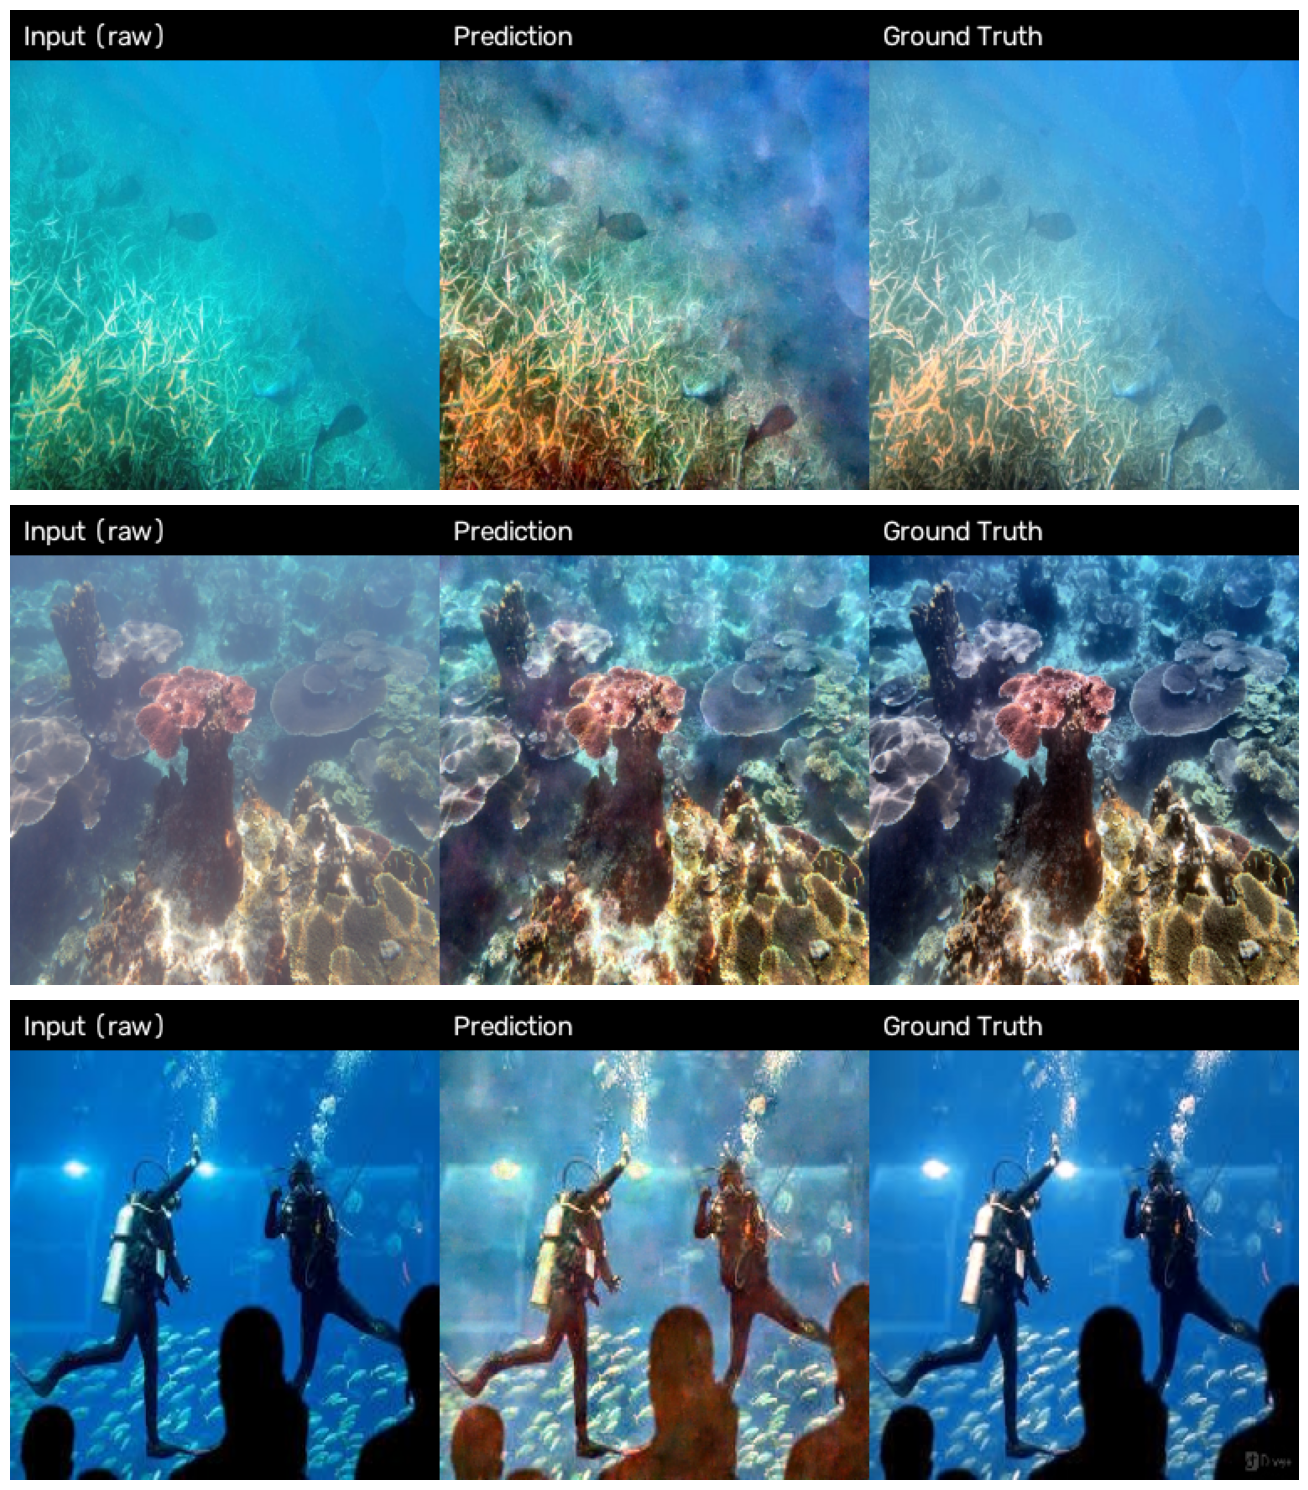

In [15]:
def put_title(image, title):
    """Add a black title bar ABOVE the image (the old version painted over the top 30 px of the image)."""
    bar = np.zeros((30, image.shape[1], 3), dtype=np.uint8)
    cv2.putText(bar, title, (8, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return np.vstack([bar, image])


def save_bgr(path, rgb):
    cv2.imwrite(str(path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))


@torch.no_grad()
def dehaze_image(image_path, size=IMG_SIZE):
    """Run the model on one image; returns input, prediction and the forward-pass time in ms."""
    ema_model.eval()
    with Image.open(image_path) as im:
        rgb = np.array(im.convert("RGB"))
    rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    I = np_to_tensor(rgb).unsqueeze(0).to(DEVICE)

    sync()
    t0 = time.perf_counter()
    pred = cpdm_infer(ema_model, I, get_sample_diffusion(CPDM_SAMPLE_STEPS_TEST))
    sync()
    infer_ms = (time.perf_counter() - t0) * 1000.0

    return {"input": rgb, "prediction": tensor_to_uint8(pred), "infer_ms": infer_ms}


def compare_one(raw_path, ref_path, output_dir):
    stem = Path(raw_path).stem
    o = dehaze_image(raw_path)

    with Image.open(ref_path) as im:
        gt = cv2.resize(np.array(im.convert("RGB")), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

    panels = [put_title(o["input"], "Input (raw)"), put_title(o["prediction"], "Prediction"), put_title(gt, "Ground Truth")]

    psnr = peak_signal_noise_ratio(gt, o["prediction"], data_range=255)
    # same SSIM definition as the training code (Gaussian window, sigma=1.5)
    ssim = structural_similarity(gt, o["prediction"], channel_axis=2, data_range=255,
                                 gaussian_weights=True, sigma=1.5, use_sample_covariance=False)
    uiqm = compute_uiqm(o["prediction"])
    print(f"{stem}: PSNR={psnr:.2f} SSIM={ssim:.4f} UIQM(pred)={uiqm:.3f} inference={o['infer_ms']:.1f}ms")

    save_bgr(Path(output_dir) / f"{stem}_input.png", o["input"])
    save_bgr(Path(output_dir) / f"{stem}_prediction.png", o["prediction"])
    save_bgr(Path(output_dir) / f"{stem}_ground_truth.png", gt)
    comparison = np.hstack(panels)
    save_bgr(Path(output_dir) / f"{stem}_comparison.png", comparison)
    return comparison, {"file": Path(raw_path).name, "psnr": psnr, "ssim": ssim, "uiqm": uiqm, "infer_ms": o["infer_ms"]}


N_COMPARE = 5   # number of test images

results = [compare_one(r, g, OUTPUT_DIR) for r, g in test_pairs[:N_COMPARE]]
comparisons = [c for c, _ in results]

comparison_csv = os.path.join(LOG_DIR, "comparison_metrics.csv")
with open(comparison_csv, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["file", "psnr", "ssim", "uiqm", "infer_ms"])
    writer.writeheader()
    writer.writerows(m for _, m in results)
print(f"Saved outputs to: {OUTPUT_DIR}\nPer-image metrics saved to {comparison_csv}")

# Display first 3 comparisons
show = comparisons[:3]
if show:
    plt.figure(figsize=(18, 5 * len(show)))
    for i, c in enumerate(show):
        plt.subplot(len(show), 1, i + 1)
        plt.imshow(c)
        plt.axis("off")
    plt.tight_layout()
    plt.show()